# Estudo de caso 1 — NDVI ao longo do tempo numa região agrícola

Este notebook percorre uma análise completa de série temporal de vegetação sobre uma
área de agricultura anual em Nova Mutum (MT), usando o cliente `wtss.py`
reformulado. Ele demonstra, na ordem em que aparecem numa análise real:

1. **Consulta multi-banda**: reflectâncias e índices numa única requisição;
2. **Álgebra entre bandas**: cálculo do índice de vegetação NDVI a partir das bandas do
   infravermelho próximo (`B8A`) e do vermelho (`B04`), comparado à banda `NDVI` fornecida
   na coleção consultada;
3. **Metadados de imagem (`scale`/`offset`)**: aplicação opcional de valores `scale` e
   `offset` para conversão à unidade física da banda;
4. **Qualidade**: a banda `SCL` como critério de pixel livre de nuvens e sombras de
   nuvens, e `CLEAROB`/`TOTALOB` como medida de quantas observações entraram em cada
   composição;
5. **Fatiamento temporal**: recorte por ano agrícola e agregação por período, diretamente
   sobre o `DatetimeIndex`;
6. **Visualização**: o ciclo fenológico da cultura ao longo de três anos;
7. **Do pixel para a área**: `ts(geom=...)`, `summarize()` e `plot_map()`, as estruturas
   esparsa e densa devolvidas pela consulta, a comparação com a imagem original lida com
   `rasterio` e a exportação para formato GeoTIFF com `to_xarray()`/`to_geotiff()`;
8. **Exploração interativa**: `plot(interactive=True)` e `plot_map(interactive=True)` —
   as mesmas leituras da área em versão navegável, com `plotly` e `folium`, em que clicar
   num pixel do mapa abre a série daquele ponto;
9. **Classificação de uso do solo**: a série temporal como atributo de um classificador
   de cinco classes, com amostras rotuladas pelo TerraClass (INPE/Embrapa) e o roteiro
   clássico de árvore de decisão e floresta aleatória.

> O ponto central: cada uma dessas etapas é uma operação nativa de `pandas`. O
> cliente entrega `pandas.Series`/`DataFrame` já indexados por data, e não listas
> paralelas de valores e datas, como era o formato do cliente anterior.

## Instalação

O cliente ainda não está publicado no PyPI, então a instalação vem do repositório. As
linhas abaixo ficam comentadas para o notebook rodar num ambiente que já o tenha.

In [1]:
# Cliente reformulado (descomente para instalar):
# %pip install "git+https://github.com/suellen-m-almeida/inpe-proj.git@tg/melhorias"

# Com os extras usados neste caso (graficos interativos, xarray e exportadores):
# %pip install "wtss[interactive,xarray,io] @ git+https://github.com/suellen-m-almeida/inpe-proj.git@tg/melhorias"

# Bibliotecas de apoio as figuras, a classificacao e ao cruzamento com as colecoes
# oficiais de uso do solo (wlts):
# %pip install matplotlib seaborn geopandas rasterio scikit-learn wlts

## 1. Área e dados

| Item | Valor |
| --- | --- |
| **Coleção** | `S2-16D-2` — composição Sentinel-2 de 16 dias, 10 m |
| **Ponto** | −13.55, −56.00 (Nova Mutum, MT) |
| **Período** | 2022-09-01 a 2025-08-31 (três anos agrícolas) |
| **Bandas** | `B04` (vermelho), `B8A` (NIR), `NDVI`, `SCL`, `CLEAROB`, `TOTALOB` |

A região pratica duas safras por ano agrícola. O ano agrícola vai de setembro a agosto e não coincide com o ano civil:

- **1ª safra** — soja de verão, plantio em outubro, dossel fechado entre dezembro e
  janeiro, colheita em fevereiro;
- **2ª safra**, a *safrinha* — milho, plantio logo após a colheita da soja, com pico de
  biomassa entre abril e maio.

Entre julho e setembro vem a entressafra, com o solo exposto. Esse ciclo duplo, dois
máximos separados por uma queda curta e profunda, é o comportamento que a série de NDVI
deve revelar.

O período começa em 1º de setembro e termina em 31 de agosto justamente para acompanhar
esse calendário: são três anos agrícolas inteiros — 2022/23, 2023/24 e 2024/25 — e não
três anos civis, que cortariam cada safra ao meio, cada um com as 23 composições de 16 dias
que o cubo produz nele (seção 3).

A coleção publica composições além de agosto de 2025, como a seção 3 também imprime. O caso
para nessas três safras por causa dos rótulos da classificação do capítulo 10: eles vêm do
TerraClass no ano base 2020, o mais recente em que as duas folhas do mapeamento devolvem
classe pelo WLTS (seção 10.1). As três safras são as mais recentes que esse conjunto de
rótulos ainda sustenta, e cada safra a mais afastaria ainda mais as séries do ano dos
rótulos — a ressalva que as seções 10.1 e 10.5 registram.

Um detalhe do recorte: a consulta devolve 70 composições, e não as 69 dos três anos
agrícolas (3 × 23). A primeira, de 29/08/2022, é a composição de 16 dias que *contém* 1º
de setembro, e por isso o servidor a inclui. Ela fica fora das fatias por ano agrícola das
seções 7, 8 e 11, mas entra nas médias por mês do calendário. E essas médias não
repousam todas sobre o mesmo número de composições: como a grade de 16 dias reinicia em
1º de janeiro a cada ano, os meses não recebem sempre a mesma quantidade — agosto fica
com sete no período, outubro com quatro e novembro com cinco, contra seis dos demais. É
o mesmo descompasso entre a grade do cubo e o calendário que a seção 7.1 comenta.

In [2]:
%matplotlib inline
import os
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wtss import WTSS

warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')
plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

In [3]:
SERVICO   = 'https://data.inpe.br/bdc/wtss/v4/'
COBERTURA = 'S2-16D-2'
LATITUDE  = -13.55
LONGITUDE = -56.00
INICIO    = '2022-09-01'
FIM       = '2025-08-31'

VERMELHO  = 'B04'   # vermelho, absorvido pela clorofila
NIR       = 'B8A'   # o infravermelho proximo que esta colecao usa (o S2 tem tambem a B08)
QUALIDADE = 'SCL'   # Scene Classification Layer: a classe atribuida ao pixel

# Os tres anos agricolas do periodo. O ano agricola vai de setembro a agosto, entao
# 2022 aqui e a safra 2022/23.
ANOS_AGRICOLAS = (2022, 2023, 2024)

# A ultima safra do periodo: e ela que a secao 9 recorta em area e o capitulo 10
# classifica.
ANO_AREA    = ANOS_AGRICOLAS[-1]
ROTULO_AREA = f'{ANO_AREA}/{str(ANO_AREA + 1)[2:]}'
AREA_INICIO = f'{ANO_AREA}-09-01'
AREA_FIM    = f'{ANO_AREA + 1}-08-31'

service = WTSS(SERVICO)
coverage = service[COBERTURA]
coverage

name,common name,description,min,max,nodata,scale,center_wavelength,full_width_half_max,data_type
CLEAROB,ClearOb,,,,0.0,1.0,,,uint8
TOTALOB,TotalOb,,,,0.0,1.0,,,uint8
PROVENANCE,Provenance,,,,-1.0,1.0,,,int16
SCL,quality,,,,0.0,1.0,,,uint8
B01,coastal,,,,0.0,0.0001,,,uint16
B02,blue,,,,0.0,0.0001,,,uint16
B04,red,,,,0.0,0.0001,,,uint16
B08,nir,,,,0.0,0.0001,,,uint16
B8A,nir08,,,,0.0,0.0001,,,uint16
B09,nir09,,,,0.0,0.0001,,,uint16


## 2. Metadados das bandas

Antes de calcular qualquer coisa, é preciso saber em que unidade os números chegam.
`describe_coverage` expõe, por banda, o fator de escala (`scale`), o deslocamento
(`offset`, que este servidor declara na chave `scale_add`) e o valor reservado para
ausência de dado (`nodata`):

In [4]:
def declarado(banda, chave):
    """O valor que o servidor declara, ou 'não declarado' quando a chave vem nula."""
    valor = banda.get(chave)
    return 'não declarado' if valor is None else valor


metadados = pd.DataFrame([
    {'banda': b['name'],
     'nodata': b.get('nodata'),
     'scale': b.get('scale'),
     'offset (scale_add)': declarado(b, 'scale_add')}
    for b in coverage.attributes
    if b['name'] in (VERMELHO, NIR, 'NDVI', QUALIDADE, 'CLEAROB', 'TOTALOB')
]).set_index('banda')

metadados

,nodata,scale,offset (scale_add)
banda,,,
CLEAROB,0.0,1.0000,não declarado
TOTALOB,0.0,1.0000,não declarado
SCL,0.0,1.0000,não declarado
B04,0.0,0.0001,não declarado
B8A,0.0,0.0001,não declarado
NDVI,-9999.0,0.0001,não declarado


As reflectâncias têm `scale = 1e-4`: o valor bruto (*digital number*) é um inteiro que,
multiplicado pela escala, vira reflectância em `[0, 1]`. O `NDVI` usa a mesma escala e um
valor reservado de `-9999` para ausência de dado. Nenhuma das seis bandas declara
deslocamento: `scale_add` vem nulo, e a tabela mostra "não declarado" em vez de um zero que
o servidor não informou.

## 3. Recuperação da série

Uma única requisição traz todas as bandas. A consulta é preguiçosa, ou seja, nada vai à rede
até o atributo `.ts` ser acessado.

In [5]:
consulta = coverage.ts(
    attributes=[VERMELHO, NIR, 'NDVI', QUALIDADE, 'CLEAROB', 'TOTALOB'],
    latitude=LATITUDE, longitude=LONGITUDE,
    start_datetime=INICIO, end_datetime=FIM,
)
ts = consulta.ts
ts

pixel id,timeseries
0,"[0.1952, 0.1884, 0.158, 0.1799, 0.7361, 0.0701, 0.0398, 0.4983, 0.0349, 0.0384, 0.0754, 0.1507, 0.1118, 0.0553, 0.019, 0.0282, 0.0271, 0.0317, 0.0782, 0.095, 0.2394, 0.2393, 0.2302, 0.157, 0.2697, 0.1372, 0.1718, 0.0771, 0.0265, 0.0297, 0.0208, 0.0235, 0.0462, 0.0224, 0.1269, 0.1124, 0.0347, 0.0408, 0.0442, 0.0479, 0.065, 0.0923, 0.1864, 0.1819, 0.182, 0.1901, 0.2297, 0.2174, 0.2001, 0.1412, 0.0762, 0.2635, 0.0731, 0.3695, 0.4262, 0.0449, 0.1631, 0.1952, 0.0474, 0.0327, 0.0184, 0.0206, 0.0248, 0.0392, 0.0792, 0.1504, 0.1649, 0.1752, 0.1839, 0.2135]"
pixel id,timeseries
0,"[0.316, 0.2887, 0.2464, 0.2972, 0.7529, 0.3083, 0.607, 0.6675, 0.8623, 0.5589, 0.3557, 0.2367, 0.1939, 0.3134, 0.4743, 0.5272, 0.3968, 0.3954, 0.2977, 0.1864, 0.3907, 0.3895, 0.3864, 0.2668, 0.3555, 0.2262, 0.2914, 0.1649, 0.4627, 0.4143, 0.4363, 0.295, 0.226, 0.0368, 0.2301, 0.263, 0.23, 0.3273, 0.2843, 0.2784, 0.2074, 0.1747, 0.3132, 0.2988, 0.3016, 0.317, 0.3698, 0.3647, 0.3235, 0.231, 0.107, 0.3917, 0.2924, 0.5623, 0.6099, 0.3523, 0.2995, 0.3067, 0.3481, 0.5116, 0.421, 0.3839, 0.3732, 0.2932, 0.2233, 0.2384, 0.2528, 0.2672, 0.2682, 0.3016]"
pixel id,timeseries
0,"[0.2363, 0.2102, 0.2185, 0.2458, 0.0112, 0.6294, 0.8769, 0.1451, 0.9222, 0.8714, 0.6501, 0.2219, 0.2685, 0.7, 0.9229, 0.8984, 0.8721, 0.8515, 0.5839, 0.3248, 0.2401, 0.2388, 0.2533, 0.259, 0.1372, 0.2449, 0.2582, 0.3628, 0.8916, 0.8662, 0.9089, 0.8524, 0.6605, 0.2432, 0.289, 0.4011, 0.7378, 0.7783, 0.7308, 0.7064, 0.5227, 0.3086, 0.2538, 0.2431, 0.2473, 0.2502, 0.2336, 0.253, 0.2356, 0.2412, 0.1681, 0.1956, 0.6, 0.2069, 0.1772, 0.7739, 0.2948, 0.2221, 0.7603, 0.8798, 0.9162, 0.8981, 0.8753, 0.7641, 0.4763, 0.2263, 0.2104, 0.2079, 0.1864, 0.171]"
pixel id,timeseries
0,"[5.0, 5.0, 5.0, 5.0, 9.0, 10.0, 4.0, 9.0, 4.0, 4.0, 4.0, 5.0, 5.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 5.0, 5.0, 5.0, 5.0, 5.0, 8.0, 5.0, 5.0, 5.0, 4.0, 4.0, 4.0, 4.0, 4.0, 7.0, 5.0, 5.0, 4.0, 4.0, 4.0, 4.0, 4.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 7.0, 9.0, 4.0, 9.0, 9.0, 4.0, 5.0, 7.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 5.0, 5.0, 5.0, 5.0, 5.0]"
pixel id,timeseries
0,"[4.0, 1.0, 1.0, 2.0, 0.0, 0.0, 2.0, 0.0, 1.0, 2.0, 1.0, 2.0, 1.0, 1.0, 2.0, 2.0, 2.0, 3.0, 3.0, 3.0, 3.0, 3.0, 2.0, 4.0, 0.0, 2.0, 2.0, 3.0, 2.0, 2.0, 1.0, 1.0, 1.0, 0.0, 1.0, 2.0, 1.0, 2.0, 3.0, 1.0, 1.0, 4.0, 3.0, 3.0, 3.0, 2.0, 4.0, 3.0, 2.0, 2.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 3.0, 1.0, 3.0, 3.0, 2.0, 6.0, 2.0, 5.0, 5.0, 3.0, 5.0, 4.0]"
pixel id,timeseries


O método `df(format='wide')` devolve um `DataFrame` indexado pela data, com uma
coluna por banda — todas alinhadas no mesmo eixo temporal:

In [6]:
dados = ts.df(format='wide')

print(f'{len(dados)} datas, de {dados.index.min():%d/%m/%Y} a {dados.index.max():%d/%m/%Y}')
print(f'índice: {type(dados.index).__name__}')
antes = len(dados[:pd.Timestamp(INICIO) - pd.Timedelta(days=1)])
print('composições por ano agrícola:',
      ', '.join(f'{ano}/{str(ano + 1)[2:]} {len(dados[f"{ano}-09-01":f"{ano + 1}-08-31"])}'
                for ano in ANOS_AGRICOLAS), f'(e {antes} antes de {INICIO})')
print(f'a coleção publica composições de {coverage.timeline[0][:10]} a {coverage.timeline[-1][:10]}')
dados.head()

70 datas, de 29/08/2022 a 29/08/2025
índice: DatetimeIndex
composições por ano agrícola: 2022/23 23, 2023/24 23, 2024/25 23 (e 1 antes de 2022-09-01)
a coleção publica composições de 2017-01-01 a 2026-09-14


attribute,B04,B8A,NDVI,SCL,CLEAROB,TOTALOB
datetime,,,,,,
2022-08-29,0.1952,0.3160,0.2363,5.0,4.0,4.0
2022-09-14,0.1884,0.2887,0.2102,5.0,1.0,3.0
2022-09-30,0.1580,0.2464,0.2185,5.0,1.0,3.0
2022-10-16,0.1799,0.2972,0.2458,5.0,2.0,3.0
2022-11-01,0.7361,0.7529,0.0112,9.0,0.0,2.0


## 4. Álgebra entre bandas — cálculo do NDVI

O NDVI contrasta a forte absorção da clorofila no vermelho com a alta reflectância da
estrutura foliar no infravermelho próximo:

$$\mathrm{NDVI} = \frac{\rho_{NIR} - \rho_{RED}}{\rho_{NIR} + \rho_{RED}}$$

Como as duas bandas vieram alinhadas no mesmo `DataFrame`, a fórmula é escrita
literalmente e o `pandas` cuida do alinhamento por data:

In [7]:
dados['NDVI_calculado'] = (
    (dados[NIR] - dados[VERMELHO]) / (dados[NIR] + dados[VERMELHO])
)

# A mascara de qualidade so entra na secao 6; aqui basta exigir que a composicao tenha
# tido ao menos uma observacao limpa, senao a comparacao pega pixel de nuvem.
com_observacao = dados['CLEAROB'] > 0
diferenca = (dados['NDVI_calculado'] - dados['NDVI']).where(com_observacao).abs()
print(f'maior diferença nas {diferenca.notna().sum()} datas com observação limpa: '
      f'{diferenca.max():.1e} ({int((diferenca <= 1e-4).sum())} delas dentro de 1e-4)')

discrepantes = diferenca > 1e-4
print(f'datas acima de 1e-4: {int(discrepantes.sum()) or "nenhuma"}')
if discrepantes.any():
    print(dados.loc[discrepantes, [VERMELHO, NIR, 'NDVI_calculado', 'NDVI', QUALIDADE]]
          .assign(diferenca=diferenca[discrepantes]).round(4).to_string())

dados[[VERMELHO, NIR, 'NDVI_calculado', 'NDVI']].head()

maior diferença nas 60 datas com observação limpa: 9.8e-05 (60 delas dentro de 1e-4)
datas acima de 1e-4: nenhuma


attribute,B04,B8A,NDVI_calculado,NDVI
datetime,,,,
2022-08-29,0.1952,0.3160,0.236307,0.2363
2022-09-14,0.1884,0.2887,0.210228,0.2102
2022-09-30,0.1580,0.2464,0.218595,0.2185
2022-10-16,0.1799,0.2972,0.245860,0.2458
2022-11-01,0.7361,0.7529,0.011283,0.0112


Como esta coleção publica o `NDVI` pronto, o cálculo foi conferido contra ele: nas 60
datas com observação limpa, as duas versões coincidem até a resolução de armazenamento da
banda (`scale = 1e-4`). A maior diferença é `9.8e-5`, e nenhuma data passa de `1e-4`.

A origem dessas diferenças pequenas está no armazenamento. O cálculo aqui roda em ponto
flutuante, enquanto a banda publicada é gravada como inteiro com `scale`, o que corta
casas decimais. Esse truncamento explica diferenças na ordem de `1e-4`, exatamente a
faixa observada.

## 5. Metadados de imagem: `scale` e `offset` são *opcionais*

O cliente expõe os *flags* `apply_scale` e `mask_nodata`, que aplicam os metadados da
seção 2 do lado do cliente. Nesta coleção, porém, o servidor já entrega os valores em
unidade física, assim, as reflectâncias saíram em `[0, 1]`, não como inteiros.

Duas versões diferentes aparecem neste notebook, e convém não confundi-las. O `v4` da URL
`https://data.inpe.br/bdc/wtss/v4/` identifica a versão da API do servidor. A versão do
cliente é outra coisa, impressa pela célula abaixo, e é dela que se trata quando o
texto fala em "cliente reformulado".

Aplicar a escala de novo seria multiplicar por `1e-4` duas vezes. O cliente detecta e
avisa antes que isso corrompa a análise:

In [8]:
import wtss

print(f'cliente wtss.py : {wtss.__version__}')
print(f'API do servidor : {SERVICO}')

cliente wtss.py : 2.0.0a4
API do servidor : https://data.inpe.br/bdc/wtss/v4/


In [9]:
with warnings.catch_warnings(record=True) as capturados:
    warnings.simplefilter('always')
    escalado_duas_vezes = ts.series(VERMELHO, apply_scale=True)

print('Valores como o servidor entrega (já em reflectância):')
print(f'  {ts.series(VERMELHO).head(3).round(4).tolist()}')
print('\nValores após apply_scale=True (escala aplicada duas vezes):')
print(f'  {escalado_duas_vezes.head(3).tolist()}')
print('\nAviso emitido pelo cliente:')
for aviso in capturados:
    print(f'  {aviso.category.__name__}: {aviso.message}')

Valores como o servidor entrega (já em reflectância):
  [0.1952, 0.1884, 0.158]

Valores após apply_scale=True (escala aplicada duas vezes):
  [1.9520000000000003e-05, 1.8840000000000003e-05, 1.58e-05]

Aviso emitido pelo cliente:


Essa proteção foi introduzida justamente porque a aplicação de metadados é opcional e
depende do servidor: o mesmo código, apontado para uma instância que entregue *digital
numbers* crus, precisaria de `apply_scale=True`. A heurística compara a magnitude e o
tipo das amostras com a escala declarada, e falha de forma ruidosa em vez de silenciosa.

### 5.1 O `scale` é uma escolha de armazenamento

O `scale` não é um efeito que recai sobre o dado, e sim uma decisão de quem publica a
coleção. Gravar o índice como inteiro, com um fator de conversão, ocupa menos espaço que
gravá-lo em ponto flutuante, e nada impede que a mesma coleção distribua o NDVI
diretamente em `float`: é uma troca entre tamanho de arquivo e precisão.

Para a análise, o que importa é outra propriedade. Uma razão normalizada não muda quando
as duas bandas são multiplicadas pelo mesmo fator, já que numerador e denominador crescem
juntos e o quociente fica onde estava. Dá para verificar numericamente:

In [10]:
escala = float(metadados.loc[NIR, 'scale'])

# Reconstrói os inteiros crus que o servidor teria enviado sem a escala aplicada.
red_dn = dados[VERMELHO] / escala
nir_dn = dados[NIR] / escala

ndvi_dos_dn = (nir_dn - red_dn) / (nir_dn + red_dn)

print(f'NDVI a partir da reflectância física : {dados["NDVI_calculado"].iloc[1]:.6f}')
print(f'NDVI a partir dos DN crus ..........: {ndvi_dos_dn.iloc[1]:.6f}')
print(f'diferença máxima em toda a série ...: '
      f'{(ndvi_dos_dn - dados["NDVI_calculado"]).abs().max():.2e}')
print()
print(f'Já a reflectância isolada muda por 4 ordens de grandeza:')
print(f'  DN cru .............: {nir_dn.iloc[1]:,.0f}')
print(f'  reflectância física .: {dados[NIR].iloc[1]:.4f}')

NDVI a partir da reflectância física : 0.210228
NDVI a partir dos DN crus ..........: 0.210228
diferença máxima em toda a série ...: 1.11e-16

Já a reflectância isolada muda por 4 ordens de grandeza:
  DN cru .............: 2,887
  reflectância física .: 0.2887


Daí a regra prática: num índice normalizado (NDVI, EVI, NBR) o fator se cancela, e o
valor não depende de como a coleção escolheu armazenar as bandas. Já uma análise que use a
reflectância como grandeza física, seja comparação entre sensores, modelo biofísico ou
calibração, precisa da conversão aplicada.

### 5.2 Máscara de `nodata`

O `mask_nodata` substitui por `NaN` as amostras iguais ao valor reservado declarado:

In [11]:
ndvi_mascarado = ts.series('NDVI', mask_nodata=True)
reservado = float(metadados.loc['NDVI', 'nodata'])

print(f'valor reservado (nodata) para NDVI : {reservado:.0f}')
print(f'amostras substituídas por NaN ....: {int(ndvi_mascarado.isna().sum())} de {len(ndvi_mascarado)}')
print(f'mínimo observado na série ........: {ts.series("NDVI").min():.4f}')

valor reservado (nodata) para NDVI : -9999
amostras substituídas por NaN ....: 0 de 70
mínimo observado na série ........: 0.0112


Nenhuma amostra foi mascarada, e isso é informativo: o valor reservado é declarado em
*digital number* (`-9999`), mas os valores chegam já escalados. Nesta série o servidor
não devolveu ausências, então a questão não se manifesta, mas ela deixa claro que
`mask_nodata` e `apply_scale` pertencem ao mesmo par de decisões, e ambos dependem do
que a instância do serviço entrega. Para descartar pixels ruins nesta coleção, o
caminho é a banda de qualidade — que é o que fazemos a seguir.

## 6. Qualidade: quais composições são aproveitáveis

Esta coleção traz duas informações de qualidade, que respondem a perguntas diferentes.

A banda `SCL` (*Scene Classification Layer*) é a mais direta: ela diz o que o
pixel é naquela composição. Os valores que este caso aceita como pixel aproveitável
são `4` (vegetação), `5` (solo exposto), `6` (água) e `11` (neve/gelo, inexistente
aqui); ficam de fora `3` (sombra de nuvem), `8` e `9` (nuvem de probabilidade média e
alta), `10` (cirrus fino), `2` (área escura), `1` (saturado ou com defeito) e `0` (sem
dado). O `7` (*não classificado*, que o Sentinel-2 usa também para nuvem de baixa
probabilidade) é descartado por precaução, e a célula seguinte mostra o que essa escolha
custa.

`CLEAROB` e `TOTALOB` respondem outra coisa: quantas observações livres de nuvem
entraram na composição de 16 dias, e quantas havia no total. A razão entre as duas é a
fração limpa da janela, e continua útil como medida de quão sustentada é cada
composição, mas é `SCL` que decide se a composição entra na série.

composições reprovadas pelo SCL: 10 de 70 (14%)
meses em que caem: jan, fev, set, out, nov, dez
meses de menor fração limpa média: fev (0.28), jan (0.31), nov (0.33)
mês de maior fração limpa média: jul (0.96)
composições por mês do calendário: jan 6, fev 6, mar 6, abr 6, mai 6, jun 6, jul 6, ago 7, set 6, out 4, nov 5, dez 6


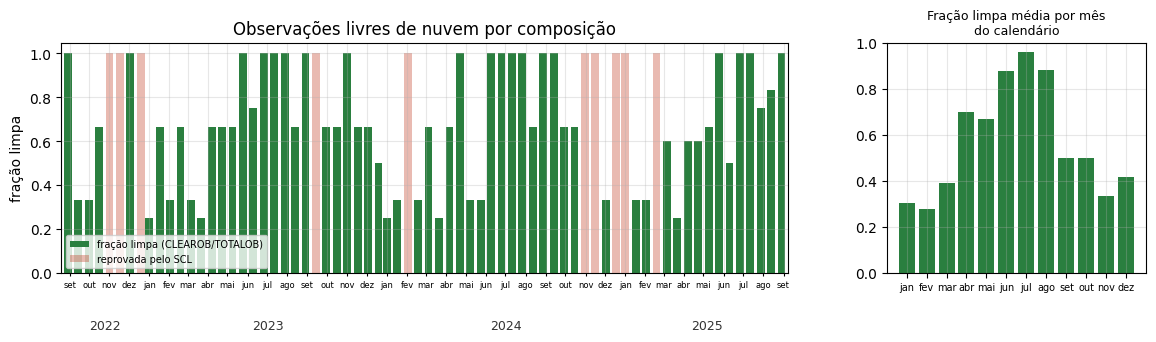

In [12]:
import matplotlib.ticker as mticker

# SCL: a classe que o Sentinel-2 atribui ao pixel na composicao.
SCL_LIMPOS = (4, 5, 6, 11)      # vegetacao, solo exposto, agua, neve/gelo
SCL_NOMES = {0: 'sem dado', 1: 'saturado/defeito', 2: 'área escura',
             3: 'sombra de nuvem', 4: 'vegetação', 5: 'solo exposto', 6: 'água',
             7: 'não classificado', 8: 'nuvem (prob. média)', 9: 'nuvem (prob. alta)',
             10: 'cirrus fino', 11: 'neve/gelo'}
MESES = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun',
         'jul', 'ago', 'set', 'out', 'nov', 'dez']

limpo = dados[QUALIDADE].isin(SCL_LIMPOS)
dados['fracao_limpa'] = dados['CLEAROB'] / dados['TOTALOB']

fig, (ax, ax_mes) = plt.subplots(
    1, 2, figsize=(14, 3.6), gridspec_kw={'width_ratios': [2.8, 1]})

ax.bar(dados.index[limpo], dados.loc[limpo, 'fracao_limpa'], width=12,
       color='#2a7f3f', label='fração limpa (CLEAROB/TOTALOB)')
# Reprovada pelo SCL a barra sumiria (ou enganaria): marca a composicao com uma faixa
# translucida de altura 1.
ax.bar(dados.index[~limpo], 1, width=12, color='#c23b22', alpha=0.35,
       label='reprovada pelo SCL')

# Uma marca por mes ao longo de todo o periodo. O nome vem de MESES, e nao do
# DateFormatter, que usaria o locale do sistema e sairia em ingles.
ax.set_xlim(dados.index.min() - pd.Timedelta(days=10),
            dados.index.max() + pd.Timedelta(days=10))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: MESES[mdates.num2date(x).month - 1]))
ax.tick_params(axis='x', labelsize=6, length=2)

# O ano vai numa segunda linha, centrado no trecho visivel de cada ano civil. Como marca
# menor ele colidiria com a marca mensal de 1o de janeiro, e o matplotlib descarta a
# marca menor que coincide com uma maior.
esquerda, direita = ax.get_xlim()
for ano in sorted({d.year for d in dados.index}):
    de = max(esquerda, mdates.date2num(pd.Timestamp(f'{ano}-01-01')))
    ate = min(direita, mdates.date2num(pd.Timestamp(f'{ano}-12-31')))
    ax.text((de + ate) / 2, -0.20, str(ano), transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=9, color='#333', clip_on=False)

ax.set_ylabel('fração limpa')
ax.set_title('Observações livres de nuvem por composição')
ax.legend(fontsize=7, loc='lower left')

# O que sustenta qualquer leitura sazonal: a media por mes do calendario.
por_mes_limpo = dados['fracao_limpa'].groupby(dados.index.month).mean().reindex(range(1, 13))
ax_mes.bar(range(1, 13), por_mes_limpo.values, color='#2a7f3f')
ax_mes.set_xticks(range(1, 13))
ax_mes.set_xticklabels(MESES, fontsize=7)
ax_mes.set_ylim(0, 1)
ax_mes.set_title('Fração limpa média por mês\ndo calendário', fontsize=9)
fig.subplots_adjust(bottom=0.24)

reprovadas = int((~limpo).sum())
print(f'composições reprovadas pelo SCL: {reprovadas} de {len(dados)} '
      f'({100 * reprovadas / len(dados):.0f}%)')
print('meses em que caem:',
      ', '.join(MESES[m - 1] for m in sorted(dados.index[~limpo].month.unique())))
piores = por_mes_limpo.nsmallest(3)
print('meses de menor fração limpa média:',
      ', '.join(f'{MESES[m - 1]} ({v:.2f})' for m, v in piores.items()))
print(f'mês de maior fração limpa média: {MESES[por_mes_limpo.idxmax() - 1]} '
      f'({por_mes_limpo.max():.2f})')
print('composições por mês do calendário:',
      ', '.join(f'{MESES[m - 1]} {n}'
                for m, n in dados.index.month.value_counts().sort_index().items()))
plt.show()

Os dois critérios podem ser confrontados diretamente, e vale medir o quanto eles
divergem antes de escolher um:

In [13]:
por_scl     = limpo
por_clearob = dados['CLEAROB'] > 0
discordam   = por_scl ^ por_clearob

print(f'aprovadas pelo SCL {list(SCL_LIMPOS)} ....: {int(por_scl.sum())} de {len(dados)}')
print(f'aprovadas por CLEAROB > 0 ...........: {int(por_clearob.sum())} de {len(dados)}')
print(f'composições em que os dois discordam : {int(discordam.sum())}')
if discordam.any():
    print()
    print(dados.loc[discordam, [QUALIDADE, 'CLEAROB', 'TOTALOB']].to_string())

print('\nSCL das composições reprovadas:')
print(dados.loc[~limpo, QUALIDADE].map(SCL_NOMES).value_counts().to_string())

com_7 = dados[QUALIDADE].isin(list(SCL_LIMPOS) + [7])
print(f'\nse o SCL 7 (não classificado) contasse como limpo: {int(com_7.sum())} datas, '
      f'{int((com_7 & ~por_clearob).sum())} delas reprovadas pelo CLEAROB')

aprovadas pelo SCL [4, 5, 6, 11] ....: 60 de 70
aprovadas por CLEAROB > 0 ...........: 60 de 70
composições em que os dois discordam : 0

SCL das composições reprovadas:
SCL
nuvem (prob. alta)     5
não classificado       3
cirrus fino            1
nuvem (prob. média)    1

se o SCL 7 (não classificado) contasse como limpo: 63 datas, 3 delas reprovadas pelo CLEAROB


Os dois critérios aprovam exatamente as mesmas 60 composições das 70 do período, sem uma
única discordância: as dez que o `SCL` reprova — cinco de nuvem de probabilidade alta, uma
de nuvem de probabilidade média, uma de cirrus fino e três não classificadas — são
precisamente aquelas em que o `CLEAROB` é zero. A máscara desta série, portanto, não depende do critério
escolhido. E isso é um resultado em si, porque significa que a análise adiante não está
apoiada numa decisão de filtragem discutível.

A troca para o `SCL` se justifica pela clareza do que cada banda afirma. O `SCL` diz
diretamente o que o pixel é: nuvem de probabilidade alta, cirrus fino, sombra. Com o
`CLEAROB` a conclusão é indireta, conta-se quantas observações limpas entraram na
composição e infere-se, de um zero, que sobrou nuvem. O único ponto em que o critério
muda de fato é a fronteira, incluir o `SCL 7` (*não classificado*) levaria a 63
composições, três delas reprovadas pelo `CLEAROB`, e é por isso que ele fica de fora.

In [14]:
# A série de trabalho: NDVI calculado, restrito às composições que o SCL aprova.
ndvi = dados['NDVI_calculado'].where(limpo)

print(f'{ndvi.notna().sum()} datas úteis de {len(ndvi)}')

60 datas úteis de 70


## 7. Fatiamento temporal

Com um `DatetimeIndex`, o recorte por período é sintaxe nativa de `pandas`, sem
procurar índices na *timeline* nem fatiar listas paralelas.

O ano agrícola de Mato Grosso vai de setembro a agosto, e não coincide com o ano
civil. Recortá-lo é uma fatia por rótulo:

In [15]:
agricola = ndvi[f'{ANO_AREA}-09':f'{ANO_AREA + 1}-08']

print(f'ano agrícola {ROTULO_AREA}: {agricola.notna().sum()} observações úteis, '
      f'de {agricola.index.min():%d/%m/%Y} a {agricola.index.max():%d/%m/%Y}')
print(f'NDVI máximo ...: {agricola.max():.3f} em {agricola.idxmax():%d/%m/%Y}')
print(f'NDVI mínimo ...: {agricola.min():.3f} em {agricola.idxmin():%d/%m/%Y}')

ano agrícola 2024/25: 18 observações úteis, de 13/09/2024 a 29/08/2025
NDVI máximo ...: 0.916 em 07/04/2025
NDVI mínimo ...: 0.171 em 29/08/2025


Fatias mais estreitas isolam fases do ciclo. O plantio da soja concentra-se em outubro,
e o pico de dossel entre dezembro e janeiro:

In [16]:
janelas = {
    f'plantio (out/{ANO_AREA})':      ndvi[f'{ANO_AREA}-10-01':f'{ANO_AREA}-11-15'],
    'dossel fechado (dez-jan)':       ndvi[f'{ANO_AREA}-12-01':f'{ANO_AREA + 1}-01-31'],
    'colheita (fev-mar)':             ndvi[f'{ANO_AREA + 1}-02-01':f'{ANO_AREA + 1}-03-31'],
    '2a safra / safrinha (abr-mai)':  ndvi[f'{ANO_AREA + 1}-04-01':f'{ANO_AREA + 1}-05-31'],
    'entressafra (jul-ago)':          ndvi[f'{ANO_AREA + 1}-07-01':f'{ANO_AREA + 1}-08-31'],
}

pd.DataFrame({
    'observações': {k: int(v.notna().sum()) for k, v in janelas.items()},
    'NDVI médio': {k: round(float(v.mean()), 3) for k, v in janelas.items()},
    'NDVI máximo': {k: round(float(v.max()), 3) for k, v in janelas.items()},
})

,observações,NDVI médio,NDVI máximo
plantio (out/2024),1,0.241,0.241
dossel fechado (dez-jan),2,0.687,0.774
colheita (fev-mar),3,0.645,0.880
2a safra / safrinha (abr-mai),4,0.863,0.916
entressafra (jul-ago),4,0.194,0.210


### 7.1 Agregação temporal

`resample` reagrupa a série em qualquer frequência. A média mensal suaviza a variação
entre composições e deixa o ciclo anual mais legível.

Um detalhe pesa nessa leitura. A coleção é um cubo de 16 dias, de modo que uma composição
pode misturar dias de dois meses, e a agregação mensal carrega essa mistura. A análise
ficaria mais limpa com uma coleção que não fosse cubo, mas o WTSS hoje serve apenas cubos
de dados.

mês de maior NDVI: abr (0.858)
mês de menor NDVI: ago (0.228)


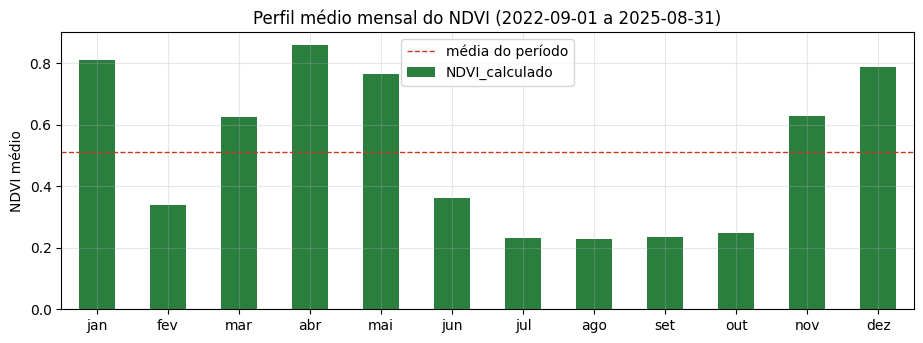

In [17]:
mensal = ndvi.resample('MS').mean()

por_mes = mensal.groupby(mensal.index.month).mean()
por_mes.index = MESES

ax = por_mes.plot(kind='bar', color='#2a7f3f', figsize=(11, 3.6), rot=0)
ax.set_ylabel('NDVI médio')
ax.set_title(f'Perfil médio mensal do NDVI ({INICIO} a {FIM})')
ax.axhline(float(ndvi.mean()), color='#c23b22', linestyle='--',
           linewidth=1, label='média do período')
ax.legend()

print(f'mês de maior NDVI: {por_mes.idxmax()} ({por_mes.max():.3f})')
print(f'mês de menor NDVI: {por_mes.idxmin()} ({por_mes.min():.3f})')

A média esconde a dispersão. Um boxplot por mês do calendário mostra, além do nível, o
quanto o NDVI varia entre os três anos e entre as composições do mesmo mês.

mês de maior dispersão: mar (amplitude 0.611)
mês de menor dispersão: out (amplitude 0.017)

composições por mês do calendário:
                jan  fev  mar  abr  mai  jun  jul  ago  set  out  nov  dez
no período        6    6    6    6    6    6    6    7    6    4    5    6
após a máscara    5    4    6    6    6    6    6    7    5    3    2    4


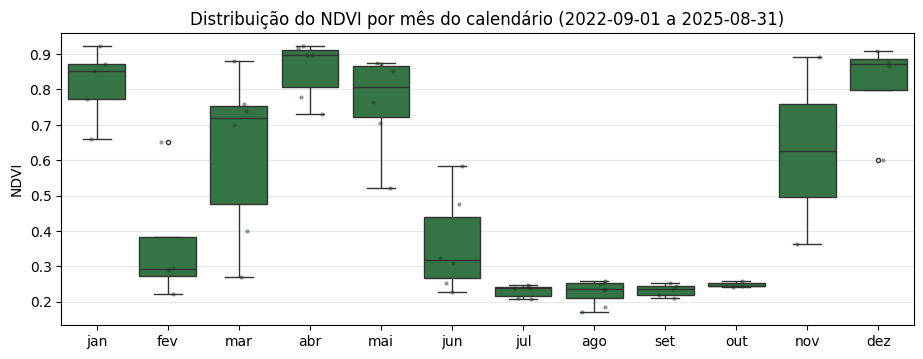

In [18]:
import seaborn as sns

por_composicao = ndvi.dropna().rename('NDVI').to_frame()
por_composicao['mês'] = pd.Categorical(
    [MESES[m - 1] for m in por_composicao.index.month], categories=MESES, ordered=True)

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.boxplot(data=por_composicao, x='mês', y='NDVI', color='#2a7f3f',
            fliersize=3, linewidth=1, ax=ax)
sns.stripplot(data=por_composicao, x='mês', y='NDVI', color='#1b3d22',
              size=3, alpha=0.5, jitter=0.18, ax=ax)
ax.set_title(f'Distribuição do NDVI por mês do calendário ({INICIO} a {FIM})')
ax.set_xlabel('')

amplitude = por_composicao.groupby('mês', observed=True)['NDVI'].agg(lambda s: s.max() - s.min())
print(f'mês de maior dispersão: {amplitude.idxmax()} (amplitude {amplitude.max():.3f})')
print(f'mês de menor dispersão: {amplitude.idxmin()} (amplitude {amplitude.min():.3f})')

# Uma caixa apoiada em poucas composicoes diz menos que as outras: conta quantas
# composicoes de cada mes existem no periodo e quantas sobrevivem a mascara da secao 6.
contagem = pd.DataFrame({
    'no período': dados.index.month.value_counts().reindex(range(1, 13), fill_value=0),
    'após a máscara': (ndvi.dropna().index.month.value_counts()
                       .reindex(range(1, 13), fill_value=0)),
})
contagem.index = MESES
print()
print('composições por mês do calendário:')
print(contagem.T.to_string())
plt.show()

O perfil é bimodal e reproduz o calendário agrícola descrito na seção 1: a subida da
soja a partir de outubro, um primeiro patamar alto entre dezembro e janeiro, a queda de
fevereiro (a colheita, com o solo momentaneamente exposto), o segundo máximo em abril
(milho de 2ª safra, o mês de maior NDVI médio, 0.858) e o vale prolongado da entressafra
entre junho e setembro, com o mínimo em agosto (0.228).

O segundo pico é o mais alto dos dois nesta média de três anos, e a tabela da seção 11
mostra por quê, em duas das três safras o máximo do ano caiu em 7 de abril, não no verão.
Vale notar que a comparação é sensível às nuvens, já que fevereiro e janeiro são os meses de
menor fração limpa no período (0.28 e 0.31, contra 0.96 em julho), então as suas médias
apoiam-se em menos observações que as dos demais. O mesmo cuidado vale para a dispersão
que o boxplot mostra: a maior é a de março (amplitude 0.611), mas a menor, a de outubro
(0.017), é a que menos se pode levar a sério, pois outubro é um dos meses com menos
composições, quatro no período e apenas três sobrevivendo à máscara da seção 6, de modo
que aquela caixa resume três números e não a variabilidade do mês. O mesmo vale, com
mais razão, para novembro: das cinco composições do mês no período, só duas passaram
pela máscara, e a caixa larga que o gráfico desenha ali vem de dois valores.

## 8. O ciclo fenológico ao longo de três anos

A série inteira do período, só com as composições que o `SCL` aprova, e uma faixa para cada
ano agrícola, de setembro a agosto. A subseção 8.1 sobrepõe os três anos num eixo comum.

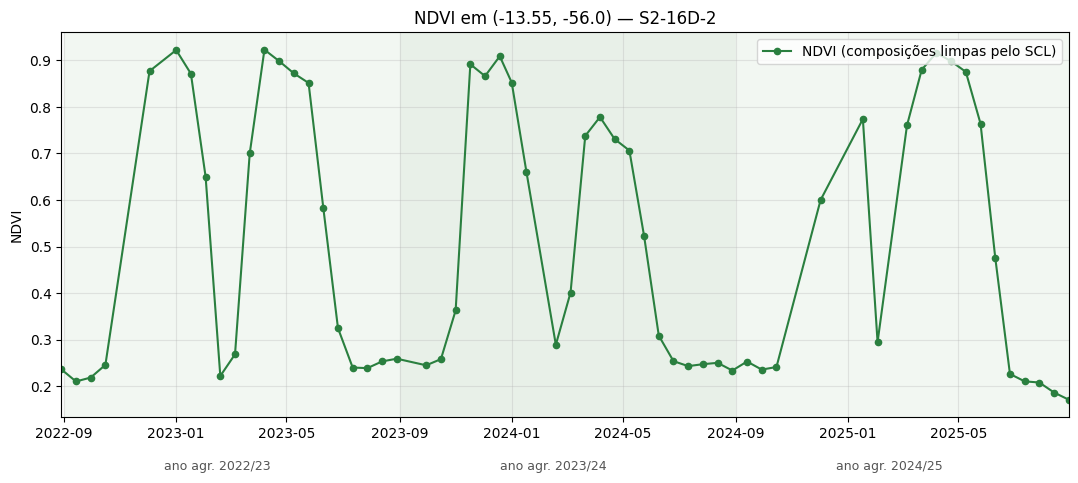

In [19]:
fig, ax = plt.subplots(figsize=(13, 5))

serie_plot = ndvi.dropna()
ax.plot(serie_plot.index, serie_plot.values, 'o-', color='#2a7f3f',
        markersize=4.5, linewidth=1.5, label='NDVI (composições limpas pelo SCL)')

# Faixas do ano agrícola (setembro a agosto).
for ano, cor in zip(ANOS_AGRICOLAS, ('#f2f7f2', '#e8f0e8', '#f2f7f2')):
    ax.axvspan(pd.Timestamp(f'{ano}-09-01'), pd.Timestamp(f'{ano + 1}-08-31'),
               color=cor, zorder=0)
    ax.text(pd.Timestamp(f'{ano + 1}-02-15'), 0.02, f'ano agr. {ano}/{str(ano + 1)[2:]}',
            ha='center', fontsize=9, color='#555')

ax.set_ylabel('NDVI')
ax.set_xlim(serie_plot.index.min(), serie_plot.index.max())
ax.set_title(f'NDVI em ({LATITUDE}, {LONGITUDE}) — {COBERTURA}')
ax.legend(loc='upper right')
plt.show()

### 8.1 Safras sobrepostas

Realinhar cada ano agrícola num eixo comum de "dias desde 1º de setembro" mostra o quanto o
calendário agrícola se repete de um ano para o outro:

primeira composição útil de cada ano agrícola:
  2022/23: NDVI 0.210 em 14/09/2022
  2023/24: NDVI 0.245 em 30/09/2023
  2024/25: NDVI 0.253 em 13/09/2024


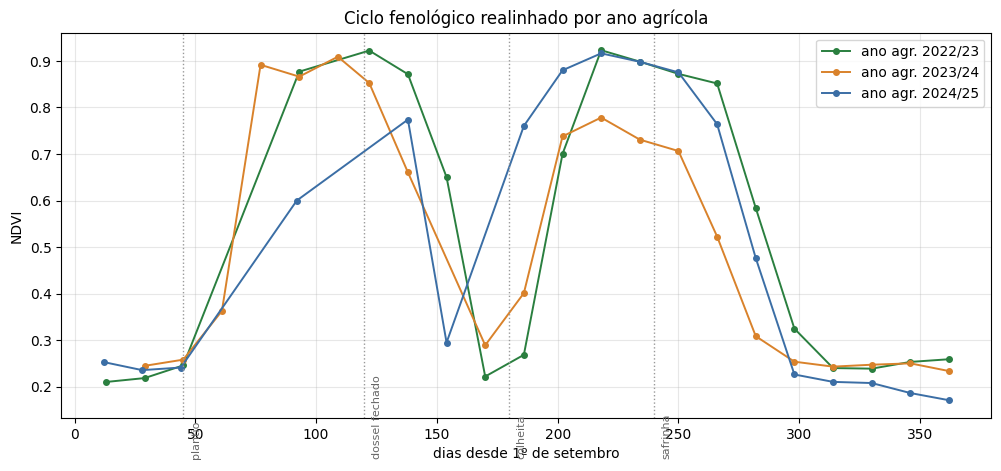

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))

for ano, cor in zip(ANOS_AGRICOLAS, ('#2a7f3f', '#d9822b', '#3b6ea5')):
    safra = ndvi[f'{ano}-09-01':f'{ano + 1}-08-31'].dropna()
    if safra.empty:
        continue
    dias = (safra.index - pd.Timestamp(f'{ano}-09-01')).days
    ax.plot(dias, safra.values, 'o-', color=cor, markersize=4, linewidth=1.4,
            label=f'ano agr. {ano}/{str(ano + 1)[2:]}')

marcos = {'plantio': 45, 'dossel fechado': 120, 'colheita': 180, 'safrinha': 240}
for rotulo, dia in marcos.items():
    ax.axvline(dia, color='#999', linestyle=':', linewidth=1)
    ax.text(dia + 3, 0.05, rotulo, rotation=90, fontsize=8, color='#666')

ax.set_xlabel('dias desde 1º de setembro')
ax.set_ylabel('NDVI')
ax.set_title('Ciclo fenológico realinhado por ano agrícola')
ax.legend()

print('primeira composição útil de cada ano agrícola:')
for ano in ANOS_AGRICOLAS:
    safra = ndvi[f'{ano}-09-01':f'{ano + 1}-08-31'].dropna()
    print(f'  {ano}/{str(ano + 1)[2:]}: NDVI {safra.iloc[0]:.3f} em {safra.index[0]:%d/%m/%Y}')
plt.show()

Os três anos agrícolas traçam a mesma curva em duas corcovas: solo exposto em
setembro (NDVI entre 0.21 e 0.25 na primeira composição útil de cada ano), subida com a emergência da soja, patamar alto no
fechamento do dossel, a queda abrupta da colheita e a segunda subida do milho safrinha,
antes do retorno ao solo exposto.

O que varia entre eles é a posição e a profundidade do vale de colheita, a janela em que
o calendário de fato se desloca de uma safra para a outra, e a altura relativa das duas
corcovas: em 2022/23 e 2024/25 o máximo do ano ficou na safrinha, em 7 de abril, e em
2023/24 ficou na soja, em 19 de dezembro. Já as datas do mínimo da entressafra
ficam próximas, entre o fim de agosto e meados de setembro (tabela da seção 11).

## 9. Da amostra pontual para a área

Toda a análise até aqui descreve um pixel de 10 m. A pergunta que falta é se ele
representa a lavoura à sua volta, já que um pixel pode cair numa falha de plantio, numa carreira
de máquina ou na borda com a estrada, e contar uma história que não é a do conjunto.

Responder isso exige trocar o ponto por uma área. A consulta é a mesma, com `geom` no
lugar de `latitude`/`longitude`.

> A área usada aqui é uma caixa de 0.004° centrada no ponto, com 433 m de leste a oeste e
> 443 m de norte a sul: é a vizinhança do pixel, não um talhão. Um talhão é a unidade de
> manejo da propriedade (mesma cultura, mesma data de plantio), de contorno irregular e
> definido pelo cadastro rural; usá-lo exigiria o polígono da fazenda, que o WTSS aceita
> em `geom` do mesmo jeito.

In [21]:
import shapely.geometry

LADO = 0.004   # graus; o tamanho em metros e impresso abaixo

caixa = shapely.geometry.box(LONGITUDE - LADO / 2, LATITUDE - LADO / 2,
                             LONGITUDE + LADO / 2, LATITUDE + LADO / 2)

area = coverage.ts(attributes=['NDVI', QUALIDADE], geom=caixa,
                     start_datetime=AREA_INICIO, end_datetime=AREA_FIM).ts

from pyproj import Geod

geod = Geod(ellps='WGS84')
oeste, sul, leste, norte = caixa.bounds
print(f'caixa .............: {geod.inv(oeste, LATITUDE, leste, LATITUDE)[2]:.0f} m (leste-oeste) x '
      f'{geod.inv(LONGITUDE, sul, LONGITUDE, norte)[2]:.0f} m (norte-sul)')
print(f'ano agrícola ......: {ROTULO_AREA} ({AREA_INICIO} a {AREA_FIM})')
print(f'pixels na área ....: {len(area.locations)}')
print(f'datas .............: {len(area.timeline)}')

caixa .............: 433 m (leste-oeste) x 443 m (norte-sul)
ano agrícola ......: 2024/25 (2024-09-01 a 2025-08-31)
pixels na área ....: 1903
datas .............: 23


### 9.1 O pixel contra a vizinhança

`summarize()` pede ao servidor as estatísticas por data (mediana, quartis, média,
desvio) em vez de trazer todos os pixels e agregá-los aqui. Comparar a série do pixel
com a mediana da vizinhança mostra se ele é representativo.

datas em que os dois são comparáveis: 19
diferença absoluta média do pixel para a mediana da área .....: 0.010
  a mesma média, descartados os dois maiores afastamentos ....: 0.004
três maiores afastamentos:
  0.110 em 02/12/2024
  0.025 em 10/06/2025
  0.013 em 29/08/2025


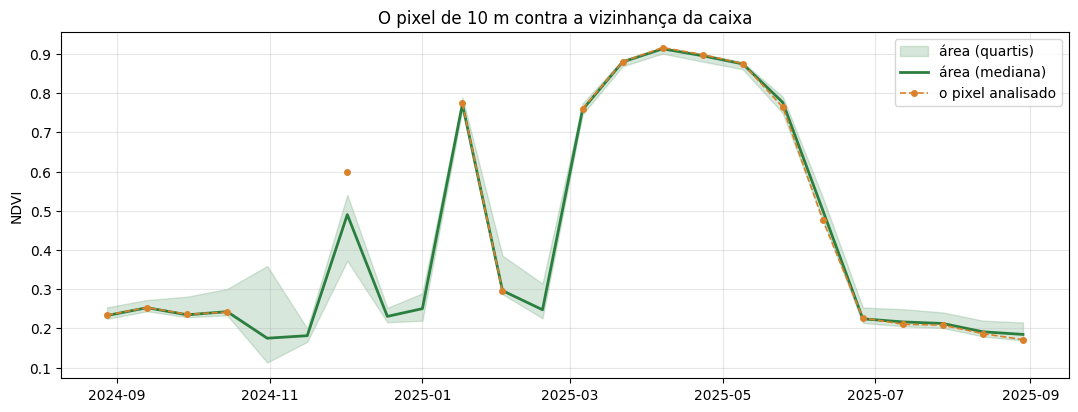

In [22]:
resumo_area = coverage.summarize(attributes=['NDVI'], geom=caixa,
                            start_datetime=AREA_INICIO, end_datetime=AREA_FIM)

agregacoes = resumo_area.values('NDVI')
datas_area = pd.to_datetime([str(d)[:10] for d in resumo_area.timeline])

comparacao = pd.DataFrame({
    'área (mediana)': agregacoes.values('median'),
    'área (q1)': agregacoes.values('q1'),
    'área (q3)': agregacoes.values('q3'),
}, index=datas_area)
comparacao['pixel'] = ndvi.reindex(comparacao.index)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.fill_between(comparacao.index, comparacao['área (q1)'], comparacao['área (q3)'],
                color='#2a7f3f', alpha=0.18, label='área (quartis)')
ax.plot(comparacao.index, comparacao['área (mediana)'], color='#2a7f3f',
        linewidth=2, label='área (mediana)')
ax.plot(comparacao.index, comparacao['pixel'], 'o--', color='#d9822b',
        markersize=4, linewidth=1.2, label='o pixel analisado')
ax.set_ylabel('NDVI')
ax.set_title('O pixel de 10 m contra a vizinhança da caixa')
ax.legend()

desvio = (comparacao['pixel'] - comparacao['área (mediana)']).abs()
dois_maiores = desvio.nlargest(2)

print(f'datas em que os dois são comparáveis: {int(desvio.notna().sum())}')
print(f'diferença absoluta média do pixel para a mediana da área .....: {desvio.mean():.3f}')
print(f'  a mesma média, descartados os dois maiores afastamentos ....: '
      f'{desvio.drop(dois_maiores.index).mean():.3f}')
print('três maiores afastamentos:')
for data, valor in desvio.nlargest(3).items():
    print(f'  {valor:.3f} em {data:%d/%m/%Y}')

O pixel acompanha a mediana da vizinhança de perto: nas 19 datas comparáveis, a
diferença absoluta média entre os dois é de 0.010, e cai para 0.004 descartados os dois
maiores afastamentos, 0.110 em 02/12/2024 e 0.025 em 10/06/2025. O terceiro já é de 0.013.
O pixel é representativo da lavoura à volta.

### 9.2 As estruturas devolvidas pela consulta por área

A mesma consulta da seção 9 pode ser lida em quatro formatos, e a escolha entre eles muda o tamanho em memória e o que dá para fazer depois. Nenhuma consulta nova é
feita aqui, é sempre o objeto `area`.

Os dois primeiros são `pandas`. No formato longo, cada linha é uma observação, com o
índice identificando data, atributo e pixel.

In [23]:
longo = area.df(format='long')

print(f'shape ..: {longo.shape[0]} linhas x {longo.shape[1]} coluna')
print(f'índice .: {longo.index.names}')
longo.head()

shape ..: 87538 linhas x 1 coluna
índice .: ['datetime', 'attribute', 'location']


,,,value
datetime,attribute,location,
2024-09-13,NDVI,"(-55.998326482354365, -13.548000493177257)",0.2544
2024-09-29,NDVI,"(-55.998326482354365, -13.548000493177257)",0.2390
2024-10-15,NDVI,"(-55.998326482354365, -13.548000493177257)",0.2606
2024-10-31,NDVI,"(-55.998326482354365, -13.548000493177257)",0.1480
2024-11-16,NDVI,"(-55.998326482354365, -13.548000493177257)",0.2090


No formato largo, a data vira o índice e as colunas passam a ser o par
`(atributo, pixel)`, o pixel identificado pela coordenada do seu centro. Como a consulta
pediu `NDVI` e `SCL`, o número de colunas é o dobro do de pixels. É a forma que
alimenta as contas por data da seção 9.1.

In [24]:
largo_estrutura = area.df(format='wide')

print(f'shape ..: {largo_estrutura.shape[0]} datas x {largo_estrutura.shape[1]} colunas')
print(f'colunas : {largo_estrutura.columns.names} (atributo e pixel)')
largo_estrutura.iloc[:4, :3]

shape ..: 23 datas x 3806 colunas
colunas : ['attribute', 'location'] (atributo e pixel)


attribute                                        NDVI  \
location   (-56.001999739810294, -13.550112751299004)   
datetime                                                
2024-09-13                                     0.4487   
2024-09-29                                     0.6102   
2024-10-15                                     0.6527   
2024-10-31                                     0.4478   

attribute                                             \
location   (-56.00199906873273, -13.550023705955022)   
datetime                                               
2024-09-13                                    0.5867   
2024-09-29                                    0.6707   
2024-10-15                                    0.7879   
2024-10-31                                    0.4039   

attribute                                             
location   (-56.001998397655605, -13.54993466061376)  
datetime                                              
2024-09-13                                    0.6069  
2024-09-29                                    0.6783  
2024-10-15                                    0.8126  
2024-10-31                                    0.3768

Os dois seguintes são `xarray`. Sem argumento, `to_xarray()` devolve a forma esparsa:
uma lista de séries sob a dimensão `location`, sem noção de vizinhança. Os pixels poderiam
estar espalhados por todo o estado que a estrutura seria a mesma.

In [25]:
esparso = area.to_xarray()

print('dimensões:', dict(esparso.sizes))
esparso

dimensões: {'time': 23, 'location': 1903}


<xarray.Dataset> Size: 746kB
Dimensions:    (time: 23, location: 1903)
Coordinates:
  * time       (time) datetime64[us] 184B 2024-09-13 2024-09-29 ... 2025-08-29
  * location   (location) int64 15kB 0 1 2 3 4 5 ... 1898 1899 1900 1901 1902
    longitude  (location) float64 15kB -56.0 -56.0 -56.0 ... -56.0 -56.0 -56.0
    latitude   (location) float64 15kB -13.55 -13.55 -13.55 ... -13.55 -13.55
Data variables:
    NDVI       (time, location) float64 350kB 0.2544 0.256 ... 0.1616 0.1596
    SCL        (time, location) float64 350kB 5.0 5.0 5.0 5.0 ... 5.0 5.0 5.0

Com `grid=True` vem a forma densa: um cubo `(time, y, x)` na grade nativa da coleção, a
Albers do BDC, com pixel de 10 m. `y` e `x` são as coordenadas, em metros nessa projeção, do
centro de cada linha (de norte para sul) e de cada coluna (de oeste para leste); o CRS vai
em `attrs`, e `longitude`/`latitude` acompanham como coordenadas 2D.

In [26]:
denso = area.to_xarray(grid=True)

print('dimensões:', dict(denso.sizes))
print(f'y (norte, m): de {denso.y.values[0]:.0f} a {denso.y.values[-1]:.0f}, '
      f'passo {denso.y.values[1] - denso.y.values[0]:.0f}')
print(f'x (leste, m): de {denso.x.values[0]:.0f} a {denso.x.values[-1]:.0f}, '
      f'passo {denso.x.values[1] - denso.x.values[0]:.0f}')
denso

dimensões: {'time': 23, 'y': 46, 'x': 43}
y (norte, m): de 9825375 a 9824925, passo -10
x (leste, m): de 4786515 a 4786935, passo 10


<xarray.Dataset> Size: 760kB
Dimensions:    (time: 23, y: 46, x: 43)
Coordinates:
  * time       (time) datetime64[us] 184B 2024-09-13 2024-09-29 ... 2025-08-29
  * y          (y) float64 368B 9.825e+06 9.825e+06 ... 9.825e+06 9.825e+06
  * x          (x) float64 344B 4.787e+06 4.787e+06 ... 4.787e+06 4.787e+06
    longitude  (y, x) float64 16kB -56.0 -56.0 -56.0 -56.0 ... -56.0 -56.0 -56.0
    latitude   (y, x) float64 16kB -13.55 -13.55 -13.55 ... -13.55 -13.55 -13.55
Data variables:
    NDVI       (time, y, x) float64 364kB nan nan nan nan ... nan nan nan nan
    SCL        (time, y, x) float64 364kB nan nan nan nan ... nan nan nan nan
Attributes:
    crs:      +proj=aea +lat_0=-12 +lon_0=-54 +lat_1=-2 +lat_2=-22 +x_0=50000...
    res_x:    10.0
    res_y:    10.0

O cubo é o menor retângulo de linhas e colunas da grade que contém todos os pixels
devolvidos, e as células desse retângulo sem pixel ficam `NaN`. A célula abaixo mostra onde
elas estão e confronta a borda do retângulo com a caixa da consulta, levada para a Albers.

In [27]:
from pyproj import Transformer

vazias = np.isnan(denso['NDVI'].values).all(axis=0)   # sem pixel em nenhuma data
print(f'células do retângulo : {vazias.size} ({vazias.shape[0]} linhas x {vazias.shape[1]} colunas)')
print(f'pixels devolvidos ...: {len(area.locations)}')
print(f'células sem pixel ...: {int(vazias.sum())} — primeira linha {int(vazias[0].sum())}, '
      f'última linha {int(vazias[-1].sum())}, primeira coluna {int(vazias[1:-1, 0].sum())}, '
      f'última coluna {int(vazias[1:-1, -1].sum())}, miolo {int(vazias[1:-1, 1:-1].sum())}')

# Os cantos da caixa lon/lat na Albers, contra a linha ou coluna de centros da borda.
para_grade = Transformer.from_crs('EPSG:4326', denso.attrs['crs'], always_xy=True)
oeste, sul, leste, norte = caixa.bounds
(xno, yno), (xne, yne), (xso, yso), (xse, yse) = (
    para_grade.transform(lon, lat)
    for lon, lat in ((oeste, norte), (leste, norte), (oeste, sul), (leste, sul)))
print()
print(f'lado norte : y de {yno:.1f} (oeste) a {yne:.1f} (leste); centros da 1ª linha em y = {denso.y.values[0]:.0f}')
print(f'lado sul   : y de {yso:.1f} (oeste) a {yse:.1f} (leste); centros da última linha em y = {denso.y.values[-1]:.0f}')
print(f'lado oeste : x de {xso:.1f} (sul) a {xno:.1f} (norte); centros da 1ª coluna em x = {denso.x.values[0]:.0f}')
print(f'lado leste : x de {xse:.1f} (sul) a {xne:.1f} (norte); centros da última coluna em x = {denso.x.values[-1]:.0f}')
print(f'inclinação do lado norte em relação às linhas da grade: '
      f'{np.degrees(np.arctan2(yne - yno, xne - xno)):.2f}°')

células do retângulo : 1978 (46 linhas x 43 colunas)
pixels devolvidos ...: 1903
células sem pixel ...: 75 — primeira linha 39, última linha 16, primeira coluna 20, última coluna 0, miolo 0

lado norte : y de 9825372.3 (oeste) a 9825375.3 (leste); centros da 1ª linha em y = 9825375
lado sul   : y de 9824923.1 (oeste) a 9824926.1 (leste); centros da última linha em y = 9824925
lado oeste : x de 4786516.5 (sul) a 4786513.3 (norte); centros da 1ª coluna em x = 4786515
lado leste : x de 4786943.0 (sul) a 4786939.8 (norte); centros da última coluna em x = 4786935
inclinação do lado norte em relação às linhas da grade: 0.41°


As 75 células vazias estão todas na borda: 39 na primeira linha, 16 na última e 20 na
primeira coluna, nenhuma na última coluna nem no miolo. Na Albers, os lados da caixa lon/lat
ficam inclinados 0.41° em relação às linhas da grade. O lado norte vai de 9825372.3 m, a
oeste, a 9825375.3 m, a leste, e cruza a linha de centros da primeira linha, em 9825375 m:
só a ponta leste dela fica dentro da caixa. O lado sul cruza da mesma forma a última linha, e
o lado oeste a primeira coluna. O lado leste fica a leste de todos os centros da última
coluna, e ela sai completa.

Comparando as quatro lado a lado:

In [28]:
import numpy as np

nan_denso = float(np.isnan(denso['NDVI'].values).mean() * 100)

comparativo = pd.DataFrame([
    {'estrutura': "df(format='long')", 'forma': f'{longo.shape[0]} x {longo.shape[1]}',
     'memória (MB)': longo.memory_usage(deep=True).sum() / 1e6, 'NaN (%)': 0.0},
    {'estrutura': "df(format='wide')", 'forma': f'{largo_estrutura.shape[0]} x {largo_estrutura.shape[1]}',
     'memória (MB)': largo_estrutura.memory_usage(deep=True).sum() / 1e6, 'NaN (%)': 0.0},
    {'estrutura': 'to_xarray()', 'forma': ' x '.join(str(v) for v in esparso.sizes.values()),
     'memória (MB)': esparso.nbytes / 1e6, 'NaN (%)': 0.0},
    {'estrutura': 'to_xarray(grid=True)', 'forma': ' x '.join(str(v) for v in denso.sizes.values()),
     'memória (MB)': denso.nbytes / 1e6, 'NaN (%)': nan_denso},
]).set_index('estrutura').round(2)

comparativo

,forma,memória (MB),NaN (%)
estrutura,,,
df(format='long'),87538 x 1,1.17,0.00
df(format='wide'),23 x 3806,0.70,0.00
to_xarray(),23 x 1903,0.75,0.00
to_xarray(grid=True),23 x 46 x 43,0.76,3.79


Cada forma serve a um uso, e este caso usa as duas.

A esparsa é a dos pontos espalhados. É exatamente o que a seção 10.3 faz com as
amostras rotuladas: uma série por local, sem nenhuma relação de vizinhança entre elas, já
que os pontos estão a dezenas de quilômetros uns dos outros. Perguntar pelo pixel ao lado
não faria sentido ali.

A densa é a do recorte contíguo, e é o que permite tudo o que veio depois na seção 9:
o mapa por data, a comparação com a imagem original, o cubo espaço-temporal e a
exportação para GeoTIFF, que só existem porque os pixels formam uma grade.

O custo aparece no comparativo, e cresce com o quadrado do lado da área: dobrar o lado
quadruplica o número de pixels. Em Sentinel-2, com pixel de 10 m, esta caixa de 433 m por
443 m já devolve 1903 pixels.

### 9.3 A variação dentro da área no pico

`plot_map()` colore cada pixel pela sua posição geográfica. Com `datetime`, mostra uma
data específica em vez de uma redução do período e aqui, o dia em que o dossel da área
esteve mais fechado.

pico da área: 07/04/2025 (NDVI mediano 0.913)
no pico, os pixels vão de 0.865 a 0.924


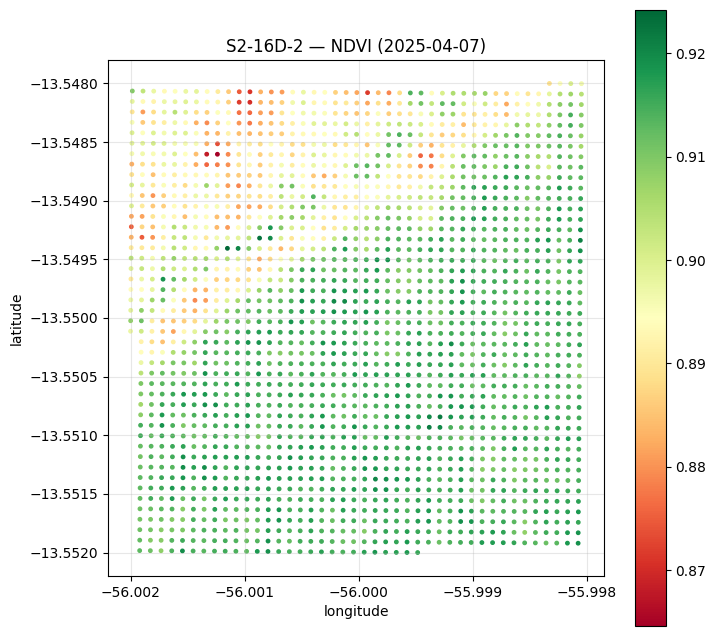

In [29]:
largo = area.df(format='wide')['NDVI']
pico = largo.median(axis=1).idxmax()

print(f'pico da área: {pico:%d/%m/%Y} (NDVI mediano {largo.median(axis=1).max():.3f})')
print(f'no pico, os pixels vão de {largo.loc[pico].min():.3f} a {largo.loc[pico].max():.3f}')

area.plot_map('NDVI', datetime=f'{pico:%Y-%m-%d}', cmap='RdYlGn', markersize=6)
plt.show()

A amplitude entre o pixel mais fraco e o mais vigoroso no auge da safra mede a
heterogeneidade da área, e o mapa mostra onde ela está, o que uma série temporal sozinha
não diz. Nesta data os pixels vão de 0.865 a 0.924, pouco para uma lavoura em pleno
dossel, mas a seção 10.8 mostra que parte dessa variação não vem da lavoura. Há um
bloco de vegetação perene no canto noroeste da caixa, que o classificador separa pixel a
pixel.

### 9.4 O mapa do cliente contra a imagem original

O mapa acima desenha um ponto por pixel devolvido pelo WTSS. Vale confrontá-lo com a
imagem de onde os valores saíram: o COG que o Brazil Data Cube publica para a mesma
data, lido com `rasterio` e um `Window` sobre a mesma caixa.

O recorte já está gravado em `recorte_cog_ndvi_20250407.tif`, um GeoTIFF de poucos KB
ao lado deste notebook, produzido por `preparar_recorte_cog.py`. Lê-lo localmente
mantém a figura reprodutível sem depender de rede nem da configuração de certificado do
ambiente; a célula seguinte, opcional, mostra o acesso remoto.

A imagem original está na Albers do Brazil Data Cube e os centros de pixel do WTSS
chegam em `EPSG:4326`, então o terceiro painel reprojeta os pontos antes de sobrepô-los.

data de pico da área .: 07/04/2025
recorte do COG .......: 2025-04-07 NDVI, 45x47 pixels, 4 KB
CRS do recorte .......: Albers do BDC (o do WTSS é EPSG:4326)
centros de pixel do WTSS dentro do recorte: 1903 de 1903


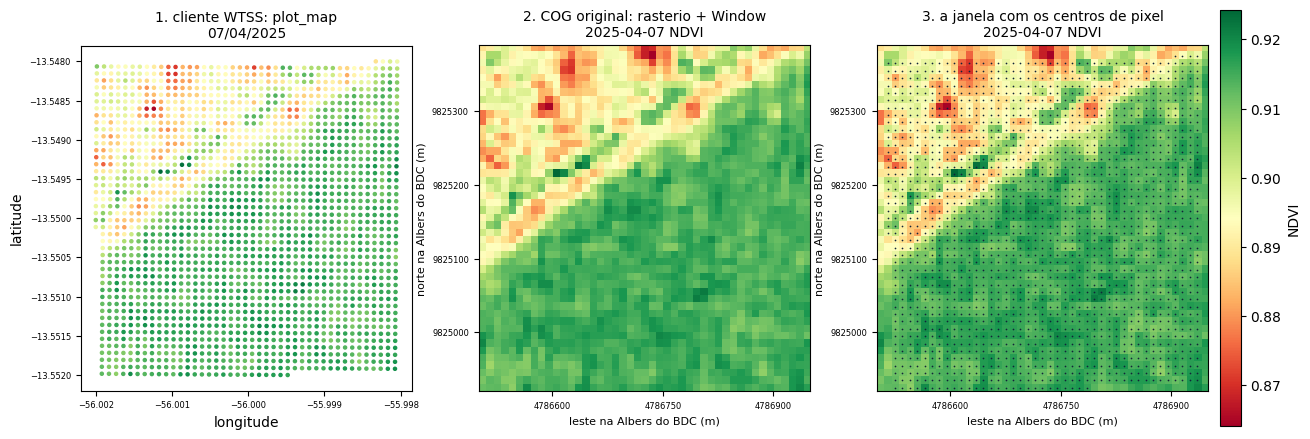

In [30]:
import rasterio
from rasterio.plot import plotting_extent
from pyproj import Transformer

RECORTE = 'recorte_cog_ndvi_20250407.tif'

with rasterio.open(RECORTE) as janela_cog:
    bruto = janela_cog.read(1, masked=True)
    extensao = plotting_extent(janela_cog)
    crs_cog = janela_cog.crs
    data_cog = janela_cog.descriptions[0]

# A banda NDVI do COG e inteira, com o mesmo scale de 1e-4 da secao 2.
ndvi_cog = bruto * float(metadados.loc['NDVI', 'scale'])
faixa = dict(vmin=float(ndvi_cog.min()), vmax=float(ndvi_cog.max()))

# Centros de pixel do WTSS, reprojetados para a Albers da imagem.
para_albers = Transformer.from_crs('EPSG:4326', crs_cog, always_xy=True)
xs, ys = para_albers.transform([p[0] for p in largo.columns],
                               [p[1] for p in largo.columns])

esquerda, direita, baixo, cima = extensao
dentro = sum(esquerda <= x <= direita and baixo <= y <= cima for x, y in zip(xs, ys))

print(f'data de pico da área .: {pico:%d/%m/%Y}')
print(f'recorte do COG .......: {data_cog}, {ndvi_cog.shape[1]}x{ndvi_cog.shape[0]} pixels, '
      f'{os.path.getsize(RECORTE) / 1024:.0f} KB')
print(f'CRS do recorte .......: Albers do BDC (o do WTSS é EPSG:4326)')
print(f'centros de pixel do WTSS dentro do recorte: {dentro} de {len(xs)}')

fig, eixos = plt.subplots(1, 3, figsize=(15, 5.4))

area.plot_map('NDVI', datetime=f'{pico:%Y-%m-%d}', cmap='RdYlGn',
              markersize=5, ax=eixos[0], legend=False, **faixa)
eixos[0].set_title(f'1. cliente WTSS: plot_map\n{pico:%d/%m/%Y}', fontsize=10)
eixos[0].ticklabel_format(useOffset=False, style='plain')

for eixo, titulo in ((eixos[1], '2. COG original: rasterio + Window'),
                     (eixos[2], '3. a janela com os centros de pixel')):
    imagem = eixo.imshow(ndvi_cog, extent=extensao, cmap='RdYlGn',
                         origin='upper', **faixa)
    eixo.set_title(f'{titulo}\n{data_cog}', fontsize=10)
    eixo.ticklabel_format(useOffset=False, style='plain')
    eixo.set_xlabel('leste na Albers do BDC (m)', fontsize=8)
    eixo.set_ylabel('norte na Albers do BDC (m)', fontsize=8)
    # Coordenadas da Albers tem 7 digitos: poucas marcas, senao os numeros colidem.
    eixo.xaxis.set_major_locator(plt.MaxNLocator(4))
    eixo.yaxis.set_major_locator(plt.MaxNLocator(5))

eixos[2].scatter(xs, ys, s=1.5, color='#12243a', linewidths=0)

for eixo in eixos:
    eixo.tick_params(labelsize=6)
    eixo.grid(False)
fig.colorbar(imagem, ax=eixos, fraction=0.02, pad=0.01, label='NDVI')
plt.show()

> **Célula opcional.** A leitura remota do COG depende de rede e de o GDAL achar um
> pacote de certificados que ele consiga abrir. No Windows, o `rasterio` aponta
> `GDAL_CURL_CA_BUNDLE` para o `cacert.pem` do `certifi`; se esse caminho tiver acento
> — `Área de Trabalho`, por exemplo — o schannel não abre o arquivo e a leitura falha
> com `CURL error: schannel: invalid path name for CA file`. A saída é copiar o
> `cacert.pem` para um caminho sem acentos e apontar `GDAL_CURL_CA_BUNDLE` para lá, que
> é o que a célula faz. Ela está em `try/except` de propósito: a figura acima não
> depende dela.

In [31]:
import pathlib
import shutil
import tempfile

COG_REMOTO = ('/vsicurl/https://data.inpe.br/bdc/data/s2-16d/v2/020/020/2025/04/07/'
              'S2-16D_V2_020020_20250407_NDVI.tif')

try:
    atual = os.environ.get('GDAL_CURL_CA_BUNDLE', '')
    if not (atual and atual.isascii() and pathlib.Path(atual).exists()):
        import certifi
        copia = pathlib.Path(tempfile.gettempdir()) / 'cacert_bdc.pem'
        if not copia.exists():
            shutil.copy(certifi.where(), copia)
        os.environ['GDAL_CURL_CA_BUNDLE'] = str(copia)
        print('GDAL_CURL_CA_BUNDLE apontado para uma cópia do cacert.pem num caminho sem acentos')

    with rasterio.open(COG_REMOTO) as remoto:
        print(f'COG remoto .....: {remoto.width}x{remoto.height} pixels de '
              f'{remoto.res[0]:.0f} m')
        print(f'nodata / dtype .: {remoto.nodata} / {remoto.dtypes[0]}')
        print('é deste arquivo que o recorte local foi extraído, com o mesmo Window.')
except Exception as erro:
    print(f'leitura remota indisponível neste ambiente: {type(erro).__name__}')
    print('a figura acima não depende disto — ela lê o recorte local.')

GDAL_CURL_CA_BUNDLE apontado para uma cópia do cacert.pem num caminho sem acentos


COG remoto .....: 10560x10560 pixels de 10 m
nodata / dtype .: -9999.0 / int16
é deste arquivo que o recorte local foi extraído, com o mesmo Window.


### 9.5 Exportação para formato GeoTIFF

O passo natural depois disso é abrir a área num SIG, cruzar com a área cadastrada e
com o mapa de solo. `to_xarray(grid=True)` remonta o raster `(time, y, x)` e
`to_geotiff()` o grava como um GeoTIFF multibanda, uma banda por data.

In [32]:
cubo_area = area.to_xarray(grid=True)
print('cubo (time, y, x):', dict(cubo_area.sizes))

destino = f'area_ano_agricola_{ANO_AREA}_{str(ANO_AREA + 1)[2:]}.tif'
area.to_geotiff(destino, attribute='NDVI')

with rasterio.open(destino) as raster:
    print(f'\n{destino}')
    print(f'  {raster.count} bandas de {raster.width}x{raster.height} pixels')
    print(f'  primeira banda .: {raster.descriptions[0]}')
    print(f'  última banda ...: {raster.descriptions[-1]}')
print(f'  tamanho ........: {os.path.getsize(destino) / 1024:.0f} KB')

cubo (time, y, x): {'time': 23, 'y': 46, 'x': 43}

area_ano_agricola_2024_25.tif
  23 bandas de 43x46 pixels
  primeira banda .: 2024-09-13
  última banda ...: 2025-08-29
  tamanho ........: 358 KB


Cada banda carrega a data como descrição. O arquivo está no CRS nativo da coleção, a
Albers do BDC, e não em lon/lat: ao abri-lo no QGIS, é nessa projeção que ele entra, a mesma
das imagens originais do BDC. É o ponto em que a análise deixa o notebook e entra no fluxo de
trabalho de quem vai usá-la.

A célula abaixo reabre o arquivo com `rasterio` e o confronta com o cubo
em memória e com o recorte do COG da seção 9.4.

In [33]:
with rasterio.open(destino) as raster:
    relido = raster.read()                     # (banda, linha, coluna)
    descricoes = list(raster.descriptions)
    transform = raster.transform
    print(f'shape (bandas, linhas, colunas): {relido.shape}')
    print(f'nº de bandas ...: {raster.count}')
    print(f'CRS igual ao da coleção ({coverage.crs.strip()}): '
          f'{raster.crs == rasterio.crs.CRS.from_user_input(coverage.crs)}')
    print(f'mesmo CRS do recorte do COG da seção 9.4: {raster.crs == crs_cog}')
    print(f'transform ......: pixel {transform.a:.0f} x {-transform.e:.0f} m, '
          f'canto noroeste em ({transform.c:.0f}, {transform.f:.0f})')
    print(f'largura x altura: {raster.width * transform.a:.0f} m x {raster.height * -transform.e:.0f} m')
    print(f'dtype / nodata .: {raster.dtypes[0]} / {raster.nodata}')

cubo_ndvi = cubo_area['NDVI'].values
print(f'\ndiferença máxima contra o cubo em memória: {np.nanmax(np.abs(relido - cubo_ndvi)):.1e}')
print(f'NaN nas mesmas células: {np.array_equal(np.isnan(relido), np.isnan(cubo_ndvi))}')

# A banda da data de pico contra o recorte do COG, célula a célula: a origem dos dois
# difere por um número inteiro de pixels.
banda_pico = relido[descricoes.index(f'{pico:%Y-%m-%d}')]
desloc_col = round((transform.c - extensao[0]) / transform.a)
desloc_lin = round((extensao[3] - transform.f) / -transform.e)
janela = ndvi_cog[desloc_lin:desloc_lin + banda_pico.shape[0],
                  desloc_col:desloc_col + banda_pico.shape[1]]
tem_valor = np.isfinite(banda_pico)
print(f'\nbanda de {pico:%d/%m/%Y} contra o COG: deslocamento de ({desloc_lin}, {desloc_col}) pixels, '
      f'{int(tem_valor.sum())} células comparadas, '
      f'diferença máxima {np.abs(banda_pico[tem_valor] - janela[tem_valor]).max():.1e}')

shape (bandas, linhas, colunas): (23, 46, 43)
nº de bandas ...: 23
CRS igual ao da coleção (+proj=aea +lat_0=-12 +lon_0=-54 +lat_1=-2 +lat_2=-22 +x_0=5000000 +y_0=10000000 +ellps=GRS80 +units=m +no_defs): True
mesmo CRS do recorte do COG da seção 9.4: True
transform ......: pixel 10 x 10 m, canto noroeste em (4786510, 9825380)
largura x altura: 430 m x 460 m
dtype / nodata .: float64 / nan

diferença máxima contra o cubo em memória: 0.0e+00
NaN nas mesmas células: True

banda de 07/04/2025 contra o COG: deslocamento de (1, 1) pixels, 1903 células comparadas, diferença máxima 1.1e-16


O arquivo relido devolve exatamente o cubo em memória, com os `NaN` nas mesmas células, e
cai sobre a grade do COG original. A banda do pico coincide com o recorte da seção 9.4 em
todas as células com valor.

### 9.6 Explorando a área de forma interativa

As figuras acima são estáticas. O cliente também entrega as mesmas leituras em versão
navegável, com o extra `interactive`: `plot()` devolve um gráfico `plotly`, e `plot_map()`
um mapa `folium` em que cada pixel abre a sua própria série ao ser clicado.

O `renderer` do `plotly` fica em `notebook_connected`, que carrega a biblioteca de CDN e
mantém o notebook leve. O `limit` reduz quantas séries são desenhadas, e o total continua
anunciado no título.

O `attributes=['NDVI']` restringe o gráfico a uma banda. É necessário aqui: a consulta
desta área também trouxe `SCL`, que é categórica, e o `summarize` do servidor não
agrega banda categórica.

In [34]:
import plotly.io as pio

pio.renderers.default = 'notebook_connected'

figura = area.plot(interactive=True, limit=200, attributes=['NDVI'])
figura.update_layout(height=420)
figura.show(config={'scrollZoom': True, 'displayModeBar': True})

No mapa, clicar num pixel abre o gráfico da série daquele ponto. O popup é SVG puro, sem
script nem recurso externo, então sobrevive ao HTML exportado.

> Num Jupyter recém-aberto o mapa pode exigir *Trust Notebook* para aparecer; no HTML
> exportado por `nbconvert` ele é exibido direto.

In [35]:
area.plot_map('NDVI', reduce='mean', cmap='RdYlGn',
              interactive=True, limit=200, radius=5)

## 10. Classificação de uso do solo

As seções 7 e 8 mostraram que um sistema de cultivo deixa um comportamento temporal no
NDVI. Se cada uso do solo tem o seu, o perfil de um ano agrícola basta para dizer o que há
num pixel. Esta seção treina um classificador para cinco classes (`floresta`,
`agricultura`, `pastagem`, `agua` e `urbano`) seguindo o roteiro clássico de árvore de
decisão em sensoriamento remoto, com uma troca: no lugar do valor de cada banda numa
imagem, o atributo de cada amostra é a série temporal inteira, e quem a extrai é o
cliente WTSS.

### 10.1 Amostras

As amostras estão em `amostras_terraclass_5classes.gpkg`, na mesma pasta deste notebook,
e os rótulos vêm do TerraClass (INPE/Embrapa), mapeamento oficial de uso e cobertura
da terra, de 30 m e derivado de imagem, a resolução mais próxima do Sentinel-2 de 10 m
usado aqui entre as coleções disponíveis. Eles foram obtidos pelo WLTS, no ano base 2020.

A região fica na fronteira dos biomas, e isso obriga a combinar as duas folhas da
coleção: `terraclass_amazonia` devolve `No-Data` fora da Amazônia Legal e
`terraclass_cerrado` devolve `No-info` fora do Cerrado. Nenhuma cobre sozinha o conjunto,
as duas juntas cobrem, e a coluna `fonte` registra de qual delas veio cada rótulo. As
classes originais foram reagrupadas nas cinco deste caso — vegetação natural florestal →
`floresta`, pastagem herbácea e arbustiva → `pastagem`, culturas agrícolas temporárias e
perenes → `agricultura`, corpo d'água → `agua`, urbanizada → `urbano`.

Cinco das 223 amostras do conjunto anterior (o da seção 10.2) ficaram de fora do
reagrupamento, por cair numa classe que não corresponde a nenhuma das cinco ou por não ter
cobertura em nenhuma das duas folhas. Restam as **218** da célula abaixo.

In [36]:
import geopandas as gpd

amostras = gpd.read_file('amostras_terraclass_5classes.gpkg')

print(f'{len(amostras)} amostras\n')
print(amostras.groupby(['classe', 'fonte']).size().to_string())

218 amostras

classe       fonte                             
agricultura  TerraClass Amazônia, ano base 2020     5
             TerraClass Cerrado, ano base 2020     53
agua         TerraClass Amazônia, ano base 2020     3
             TerraClass Cerrado, ano base 2020     42
floresta     TerraClass Amazônia, ano base 2020    25
pastagem     TerraClass Amazônia, ano base 2020    12
             TerraClass Cerrado, ano base 2020     30
urbano       TerraClass Amazônia, ano base 2020    21
             TerraClass Cerrado, ano base 2020     27


Duas ressalvas sobre o ano dos rótulos. O ano base 2020 é o mais recente em que as duas
folhas devolvem classe pelo WLTS, e usar anos diferentes em cada metade do conjunto seria
pior que usar um só. A célula abaixo confere isso: imprime o período que cada coleção declara
e consulta cinco amostras de cada bioma em 2020 e em 2022. O ano base é anterior ao período
analisado, que começa em setembro de 2022, então um ponto pode ter mudado de uso nesse
intervalo.

O WLTS limita requisições e em consultas seguidas ele passa a responder 429 (*Too Many
Requests*). A função `com_espera`, definida abaixo e usada também na seção 10.2, repete a
consulta com espera maior a cada recusa. Se ainda assim a célula falhar, basta repeti-la
depois de alguns minutos.

In [37]:
import time

import wlts

servico_wlts = wlts.WLTS('https://data.inpe.br/bdc/wlts/v1/')
recusas = {'429': 0}   # recusas por excesso de requisicoes, contadas por com_espera


def com_espera(consulta, tentativas=6):
    """Executa uma consulta ao WLTS, esperando mais a cada recusa por excesso de requisições.

    Numa resposta 429 (Too Many Requests), a espera segue o Retry-After, se o serviço o
    mandar, e senão dobra a cada tentativa, a partir de 15 s. Outras falhas de rede ganham
    uma espera curta.
    """
    for tentativa in range(1, tentativas + 1):
        try:
            return consulta()
        except Exception as erro:
            if tentativa == tentativas:
                raise
            resposta = getattr(erro, 'response', None)
            if getattr(resposta, 'status_code', None) == 429:
                recusas['429'] += 1
                espera = float(resposta.headers.get('Retry-After') or 15 * 2 ** (tentativa - 1))
                print(f'  WLTS recusou por excesso de requisições (429); nova tentativa em {espera:.0f} s')
            else:
                espera = 2 * tentativa
            time.sleep(espera)


for nome in ('ibge_cobertura_uso_terra', 'terraclass_amazonia', 'terraclass_cerrado'):
    periodo = com_espera(lambda: servico_wlts[nome])['period']
    print(f'{nome:26s}: período declarado de {periodo["start_date"]} a {periodo["end_date"]}')

print()
for colecao, bioma in (('terraclass_amazonia', 'Amazônia'), ('terraclass_cerrado', 'Cerrado')):
    pontos = amostras[amostras['fonte'].str.contains(bioma)].head(5)
    for ano in ('2020', '2022'):
        resposta = com_espera(lambda: servico_wlts.tj(
            latitude=pontos['latitude'].tolist(), longitude=pontos['longitude'].tolist(),
            collections=[colecao], start_date=ano, end_date=ano).df())
        com_classe = 0 if resposta.empty else int(
            (~resposta['class'].isin(['No-Data', 'No-info'])).sum())
        print(f'{colecao:20s} {ano}: {com_classe} de {len(pontos)} amostras com classe')

ibge_cobertura_uso_terra  : período declarado de 2000 a 2020


terraclass_amazonia       : período declarado de 2008 a 2022


terraclass_cerrado        : período declarado de 2018 a 2022



terraclass_amazonia  2020: 5 de 5 amostras com classe


terraclass_amazonia  2022: 5 de 5 amostras com classe


terraclass_cerrado   2020: 5 de 5 amostras com classe


  WLTS recusou por excesso de requisições (429); nova tentativa em 15 s


terraclass_cerrado   2022: 0 de 5 amostras com classe


A folha da Amazônia devolve classe para 2020 e para 2022. A do Cerrado declara dados até
2022, mas só devolve classe para 2020, pois em 2022 nenhuma das cinco amostras volta com classe.
O ano comum às duas é, portanto, 2020.

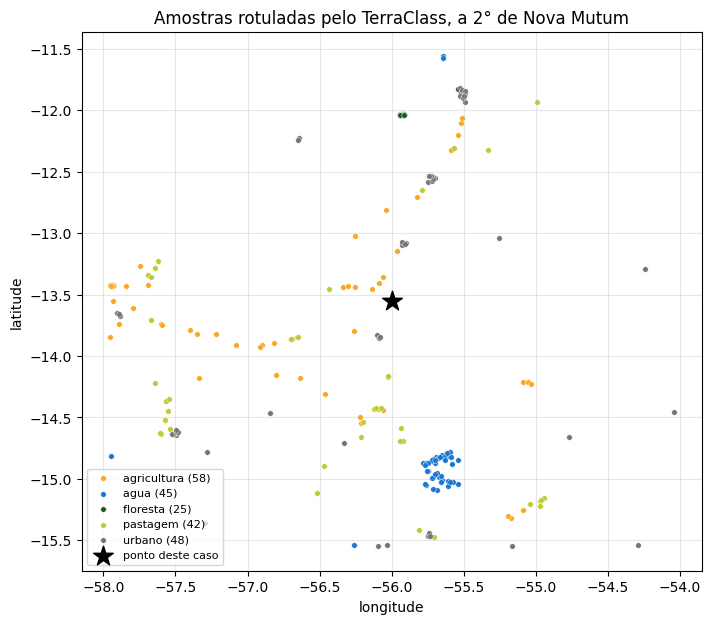

In [38]:
CORES = {'floresta': '#1b5e20', 'agricultura': '#f9a825', 'pastagem': '#c0ca33',
         'agua': '#1976d2', 'urbano': '#757575'}

fig, ax = plt.subplots(figsize=(8, 7))
for classe, grupo in amostras.groupby('classe'):
    ax.scatter(grupo['longitude'], grupo['latitude'], s=16, color=CORES[classe],
               label=f'{classe} ({len(grupo)})', edgecolor='white', linewidth=0.3)
ax.scatter([LONGITUDE], [LATITUDE], marker='*', s=220, color='black', zorder=5,
           label='ponto deste caso')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title('Amostras rotuladas pelo TerraClass, a 2° de Nova Mutum')
ax.ticklabel_format(useOffset=False, style='plain')
ax.legend(fontsize=8, loc='lower left')
plt.show()

### 10.2 As amostras contra as coleções oficiais, pelo WLTS

As 223 amostras originais deste caso, `floresta`, `pastagem` e `agricultura` do `sits`
(anos agrícolas de 2000/01 a 2015/16) e `agua` e
`urbano` sorteadas sobre o MapBiomas de 2023, ficaram guardadas em `amostras_5classes.gpkg`. Confrontá-las com os mapeamentos
oficiais é o que justifica a troca de rótulos feita em 10.1, e o WLTS faz exatamente
isso: dado um ponto, devolve a trajetória de classes que cada coleção atribui a ele ao
longo dos anos.

A consulta abaixo pede as três coleções de uma vez, no ano base de 2020 — o mais recente
em que o IBGE e as duas folhas do TerraClass devolvem classe, como a seção 10.1 mostrou. São
muitas requisições seguidas, e é aqui que o limite do WLTS costuma aparecer. Assim, a consulta usa
a função `com_espera`, e se a célula falhar, basta repeti-la depois de alguns minutos. O
tempo de consulta que a célula imprime depende sobretudo do limite de requisições do
serviço, por isso ele vem acompanhado do número de recusas 429 que a consulta sofreu.

In [39]:
COLECOES_OFICIAIS = ['ibge_cobertura_uso_terra', 'terraclass_amazonia', 'terraclass_cerrado']
ANO_OFICIAL = '2020'

amostras_antigas = gpd.read_file('amostras_5classes.gpkg')
print('origem das amostras antigas:')
print(amostras_antigas.groupby(['classe', 'fonte']).size().to_string(), '\n')


# O WLTS faz uma requisicao por ponto, entao uma falha derruba a consulta inteira. Vai em
# lotes e repete so o lote que falhar, com a espera de com_espera (secao 10.1), que e
# maior quando o servico recusa por excesso de requisicoes (429).
def trajetorias(locais, lote=40):
    partes = []
    for inicio in range(0, len(locais), lote):
        bloco = locais.iloc[inicio:inicio + lote]
        parte = com_espera(lambda: servico_wlts.tj(
            latitude=bloco['latitude'].tolist(),
            longitude=bloco['longitude'].tolist(),
            collections=COLECOES_OFICIAIS,
            start_date=ANO_OFICIAL, end_date=ANO_OFICIAL).df())
        # O WLTS numera a partir de 1, e reinicia a cada lote.
        parte['point_id'] = parte['point_id'].astype(int) - 1 + inicio
        partes.append(parte)
    return pd.concat(partes, ignore_index=True)


inicio_consulta = time.perf_counter()
recusas_antes = recusas['429']
tj = trajetorias(amostras_antigas)

print(f'{len(tj)} registros para {len(amostras_antigas)} amostras, ano base {ANO_OFICIAL}')
print(f'consulta: {time.perf_counter() - inicio_consulta:.0f} s, com '
      f'{recusas["429"] - recusas_antes} recusas 429 do WLTS\n')
print(tj.groupby('collection')['class'].value_counts().to_string())

origem das amostras antigas:
classe       fonte                                            
agricultura  sits: samples_matogrosso_mod13q1 (INPE/e-sensing)    50
agua         MapBiomas Colecao 9, cobertura 2023, classe 33       50
floresta     sits: samples_matogrosso_mod13q1 (INPE/e-sensing)    23
pastagem     sits: samples_matogrosso_mod13q1 (INPE/e-sensing)    50
urbano       MapBiomas Colecao 9, cobertura 2023, classe 24       50 



  WLTS recusou por excesso de requisições (429); nova tentativa em 15 s


  WLTS recusou por excesso de requisições (429); nova tentativa em 30 s


  WLTS recusou por excesso de requisições (429); nova tentativa em 60 s


  WLTS recusou por excesso de requisições (429); nova tentativa em 15 s


...

  WLTS recusou por excesso de requisições (429); nova tentativa em 15 s


  WLTS recusou por excesso de requisições (429); nova tentativa em 30 s


  WLTS recusou por excesso de requisições (429); nova tentativa em 60 s


  WLTS recusou por excesso de requisições (429); nova tentativa em 15 s


666 registros para 223 amostras, ano base 2020
consulta: 483 s, com 10 recusas 429 do WLTS

collection                class                                         
ibge_cobertura_uso_terra  Área Agrícola                                      72
                          Corpo d'água Continental                           40
                          Área Artificial                                    38
                          Pastagem com Manejo                                33
                          Vegetação Florestal                                25
                          Mosaico de Ocupações em Área Florestal              8
                          Mosaico de Ocupações em Área Campestre              4
                          Vegetação Campestre                                 3
terraclass_amazonia       No-Data                                           157
                          Vegetação Natural Florestal Primária               23
                          Urbanizad

In [40]:
# As legendas oficiais reagrupadas nas cinco classes deste caso. O que nao cai em
# nenhuma delas (silvicultura, mineracao, mosaicos, vegetacao campestre) fica de fora.
ROTULO_OFICIAL = {
    # TerraClass Amazonia e Cerrado
    'Vegetação Natural Florestal Primária': 'floresta',
    'Vegetação Natural Florestal Secundária': 'floresta',
    'Vegetação Natural Primária': 'floresta',
    'Vegetação Natural Secundária': 'floresta',
    'Pastagem Herbacea': 'pastagem',
    'Pastagem Arbustica/Arborea': 'pastagem',
    'Pastagem': 'pastagem',
    'Cultura Agricola Temporaria de 1 Ciclo': 'agricultura',
    'Cultura Agricola Temporaria de mais de 1 Ciclo': 'agricultura',
    'Cultura Agricola Temporária 1 ciclo': 'agricultura',
    'Cultura Agricola Temporária de Mais de 1 ciclo': 'agricultura',
    'Cultura Agricola Perene': 'agricultura',
    'Cultura Agricola SemiPerene': 'agricultura',
    'Corpo DAgua': 'agua',
    "Corpos d'água": 'agua',
    'Urbanizada': 'urbano',
    # IBGE
    'Vegetação Florestal': 'floresta',
    'Pastagem com Manejo': 'pastagem',
    'Área Agrícola': 'agricultura',
    "Corpo d'água Continental": 'agua',
    'Área Artificial': 'urbano',
}

indice = range(len(amostras_antigas))
oficial = {nome: grupo.set_index('point_id')['class'].map(ROTULO_OFICIAL).reindex(indice)
           for nome, grupo in tj.groupby('collection')}

# A regiao fica na fronteira dos biomas: nenhuma folha do TerraClass cobre tudo sozinha.
terraclass = oficial['terraclass_amazonia'].fillna(oficial['terraclass_cerrado'])
ibge = oficial['ibge_cobertura_uso_terra']
original = amostras_antigas['classe']

print(f'pontos com classe no TerraClass Amazônia : '
      f'{int(oficial["terraclass_amazonia"].notna().sum())} de {len(amostras_antigas)}')
print(f'pontos com classe no TerraClass Cerrado .: '
      f'{int(oficial["terraclass_cerrado"].notna().sum())} de {len(amostras_antigas)}')
print(f'pontos cobertos pelas duas juntas .......: '
      f'{int(terraclass.notna().sum())} de {len(amostras_antigas)}')
print(f'pontos cobertos pelo IBGE sozinho .......: '
      f'{int(ibge.notna().sum())} de {len(amostras_antigas)}')

pontos com classe no TerraClass Amazônia : 66 de 223
pontos com classe no TerraClass Cerrado .: 152 de 223
pontos cobertos pelas duas juntas .......: 218 de 223
pontos cobertos pelo IBGE sozinho .......: 208 de 223


In [41]:
concordancia = pd.DataFrame({
    'amostras': original.value_counts(),
    'IBGE concorda': (ibge == original).groupby(original).sum(),
    'TerraClass concorda': (terraclass == original).groupby(original).sum(),
})
concordancia.loc['TOTAL'] = concordancia.sum()
concordancia['IBGE %'] = (100 * concordancia['IBGE concorda'] / concordancia['amostras']).round(0)
concordancia['TerraClass %'] = (100 * concordancia['TerraClass concorda'] / concordancia['amostras']).round(0)
concordancia.index.name = 'classe da amostra'
concordancia

,amostras,IBGE concorda,TerraClass concorda,IBGE %,TerraClass %
classe da amostra,,,,,
agricultura,50,48,50,96.0,100.0
agua,50,40,45,80.0,90.0
floresta,23,21,23,91.0,100.0
pastagem,50,30,42,60.0,84.0
urbano,50,38,48,76.0,96.0
TOTAL,223,177,208,79.0,93.0


In [42]:
# Para onde vai o que nao concorda, no IBGE:
print('rótulo do IBGE por classe da amostra:')
print(pd.crosstab(original, ibge.fillna('(fora das 5 classes)')).to_string())

rótulo do IBGE por classe da amostra:
class        (fora das 5 classes)  agricultura  agua  floresta  pastagem  urbano
classe                                                                          
agricultura                     2           48     0         0         0       0
agua                            6            0    40         2         2       0
floresta                        0            2     0        21         0       0
pastagem                        1           17     0         2        30       0
urbano                          6            5     0         0         1      38


Dois resultados saem daí.

O IBGE é a única coleção que cobre as cinco classes sozinha (208 dos 223 pontos), mas
concorda com apenas 177 deles. O ponto fraco está em `pastagem`, que ele acerta em 60% e
troca por `agricultura` em 17 das 50 amostras. Não é erro grosseiro: o produto é vetorial
na escala 1:250.000, cujo polígono mínimo tem quilômetros de lado, e pasto e lavoura se
alternam em manchas muito menores que isso numa região de agricultura mecanizada. Para um
pixel de 10 m, essa generalização é grossa demais.

O TerraClass precisa das duas folhas combinadas, a da Amazônia responde por 66
pontos e a do Cerrado por 152, porque a região fica na fronteira dos biomas, mas juntas
cobrem 218 dos 223 e concordam com 208. `agricultura` e `floresta` batem em 100%,
`urbano` em 96% e `pastagem`, a classe difícil, ainda em 84%. É essa diferença, somada aos
30 m derivados de imagem contra o vetor 1:250.000 do IBGE, que justifica adotá-lo como
fonte dos rótulos na seção 10.1.

### 10.3 A série temporal como atributo

Uma consulta por amostra, pedindo `NDVI` e `SCL` juntos. O NDVI só é mantido nas
composições que o `SCL` aprova (seção 6) e as lacunas que a nuvem deixa são
preenchidas por interpolação no tempo, dentro de cada amostra. Cada série chega como
`pandas.Series` indexada por data, e o `DataFrame` que as reúne alinha as datas sozinho. O
índice de datas usado é o da área da seção 9, a mesma que será classificada no fim.

In [43]:
series = {}
for i, amostra in amostras.iterrows():
    serie = coverage.ts(attributes=['NDVI', QUALIDADE],
                        latitude=float(amostra.latitude), longitude=float(amostra.longitude),
                        start_datetime=AREA_INICIO, end_datetime=AREA_FIM).ts.df(format='wide')
    # Fica so o NDVI das composicoes que o SCL aprova.
    series[i] = serie['NDVI'].where(serie[QUALIDADE].isin(SCL_LIMPOS))

datas = largo.index                      # as datas da area da secao 9
tabela = pd.DataFrame(series).reindex(datas)
# As lacunas de nuvem sao preenchidas por interpolacao no tempo, amostra a amostra.
tabela = tabela.interpolate(method='time', limit_direction='both')

X = tabela.T.dropna()                    # descarta a amostra que continuar sem dado
X.columns = [d.strftime('%Y-%m-%d') for d in datas]
y = amostras.loc[X.index, 'classe']

print(f'{X.shape[0]} amostras x {X.shape[1]} datas ({X.columns[0]} a {X.columns[-1]})')
print(f'amostras descartadas por falta de dado: {len(amostras) - X.shape[0]}')
X.head(3)

218 amostras x 23 datas (2024-09-13 a 2025-08-29)
amostras descartadas por falta de dado: 0


,2024-09-13,2024-09-29,2024-10-15,2024-10-31,2024-11-16,2024-12-02,2024-12-18,2025-01-01,2025-01-17,2025-02-02,...,2025-04-07,2025-04-23,2025-05-09,2025-05-25,2025-06-10,2025-06-26,2025-07-12,2025-07-28,2025-08-13,2025-08-29
0,0.2725,0.2287,0.3205,0.429526,0.538551,0.647577,0.756603,0.852000,0.55035,0.248700,...,0.8879,0.8089,0.7722,0.2601,0.2583,0.2034,0.2150,0.2205,0.2062,0.2102
1,0.2562,0.1893,0.2608,0.419775,0.578750,0.737725,0.896700,0.610073,0.28250,0.172900,...,0.8986,0.8402,0.7389,0.3794,0.3239,0.2463,0.2410,0.2503,0.2037,0.1940
2,0.2504,0.2265,0.2906,0.278900,0.305700,0.539900,0.873400,0.710500,0.84960,0.665433,...,0.9148,0.8625,0.8793,0.8702,0.8039,0.3790,0.3807,0.2616,0.2448,0.2288


### 10.4 O comportamento de cada classe

amplitude do perfil médio de cada classe:
             NDVI mínimo  NDVI máximo  amplitude data do máximo
classe                                                         
agricultura        0.219        0.845      0.626     2025-04-07
agua              -0.403       -0.019      0.384     2025-02-02
floresta           0.456        0.833      0.377     2025-04-07
pastagem           0.270        0.737      0.467     2025-04-07
urbano             0.201        0.373      0.172     2025-04-07

queda entre 2025-01-01 e 2025-02-02:
classe
agricultura    0.253
agua          -0.053
floresta      -0.008
pastagem       0.021
urbano        -0.010

perfil médio de agricultura e pastagem, data a data:
classe      agricultura  pastagem
2024-09-13        0.223     0.270
2024-09-29        0.219     0.292
2024-10-15        0.239     0.392
2024-10-31        0.329     0.443
2024-11-16        0.532     0.529
2024-12-02        0.700     0.622
2024-12-18        0.770     0.661
2025-01-01        0.759     0.698


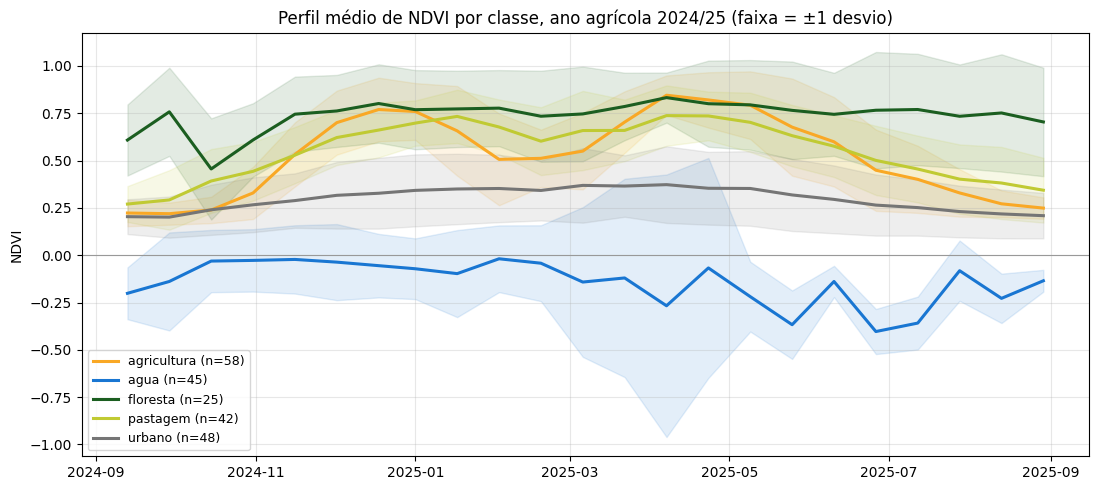

In [44]:
perfis = X.groupby(y).mean()

fig, ax = plt.subplots(figsize=(13, 5.5))
for classe in sorted(y.unique()):
    bloco = X[y == classe]
    media, desvio_classe = bloco.mean(), bloco.std()
    ax.plot(datas, media, color=CORES[classe], linewidth=2.2, label=f'{classe} (n={len(bloco)})')
    ax.fill_between(datas, media - desvio_classe, media + desvio_classe,
                    color=CORES[classe], alpha=0.12)
ax.axhline(0, color='#999', linewidth=0.8)
ax.set_ylabel('NDVI')
ax.set_title(f'Perfil médio de NDVI por classe, ano agrícola {ROTULO_AREA} (faixa = ±1 desvio)')
ax.legend(fontsize=9)

# Quanto cada classe de fato varia ao longo do ano, medido no perfil medio.
amplitudes = pd.DataFrame({
    'NDVI mínimo': perfis.min(axis=1),
    'NDVI máximo': perfis.max(axis=1),
    'amplitude': perfis.max(axis=1) - perfis.min(axis=1),
    'data do máximo': perfis.idxmax(axis=1),
}).round(3)
print('amplitude do perfil médio de cada classe:')
print(amplitudes.to_string())

# A colheita de fevereiro: a queda do maximo de verao ate o vale seguinte.
verao, vale = '2025-01-01', '2025-02-02'
print(f'\nqueda entre {verao} e {vale}:')
print((perfis[verao] - perfis[vale]).round(3).to_string())

print()
print('perfil médio de agricultura e pastagem, data a data:')
print(perfis.T[['agricultura', 'pastagem']].round(3).to_string())
plt.show()

Os cinco perfis se separam a olho. `agua` fica em torno de zero ou abaixo o ano todo.
`urbano` é baixo e plano, e é a classe de menor amplitude (0.172). `floresta` é alta e
quase plana, sem o vale da entressafra. `agricultura` é a curva bimodal das seções 7 e
8 — vale em setembro, subida da soja, queda da colheita, pico da segunda safra — e a de
maior amplitude (0.626).

`pastagem` é a intermediária, e não pela amplitude: os seus 0.467 não estão longe dos
0.626 da `agricultura`, e as duas terminam no mesmo pico de 7 de abril. O que as separa é
a *forma*. A pastagem sobe mais cedo, em 15/10 já está em 0.392 contra 0.239 da lavoura,
que ainda é solo preparado, e desce mais devagar no fim do ciclo, quando em 29/08 marca
0.343 contra 0.249. E não tem o vale profundo da colheita: entre 1º de janeiro e 2 de
fevereiro a `agricultura` perde 0.253 de NDVI, e a `pastagem`, 0.021.

As duas classes que mais se sobrepõem são justamente `pastagem` e `agricultura` na estação
chuvosa, ambas verdes, e `pastagem` e `urbano` na seca, quando o pasto seco chega perto do
NDVI de área construída. A matriz de confusão da seção 10.7 confirma exatamente esses dois
pares.

### 10.5 Treino, teste e validação cruzada

Como no roteiro: uma partição estratificada de 30% para teste, e depois validação
cruzada em cinco dobras para uma estimativa menos dependente do sorteio.

Vale reforçar o que entra como atributo. A matriz `X` montada na seção 10.3 tem uma coluna
por data e nada além: são os valores de NDVI da série, sem latitude nem longitude. A
exclusão é proposital. Com as coordenadas entre os atributos, o modelo aprenderia a
geografia das amostras, decorando onde cada classe foi coletada, em vez do comportamento
espectral-temporal que se quer medir. A célula a seguir confirma as colunas.

In [45]:
print(f'atributos: {X.shape[1]} colunas, todas datas de NDVI')
print(f'  primeira: {X.columns[0]} | última: {X.columns[-1]}')
coordenadas = [col for col in X.columns if col.lower() in ('latitude', 'longitude', 'lat', 'lon')]
print(f'  latitude ou longitude entre os atributos: {coordenadas or "nenhuma"}')

atributos: 23 colunas, todas datas de NDVI
  primeira: 2024-09-13 | última: 2025-08-29
  latitude ou longitude entre os atributos: nenhuma


In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

arvore = DecisionTreeClassifier(random_state=42).fit(X_treino, y_treino)
floresta_aleatoria = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_treino, y_treino)

print('acurácia no teste (30%):')
print(f'  árvore de decisão .: {arvore.score(X_teste, y_teste):.3f}')
print(f'  floresta aleatória : {floresta_aleatoria.score(X_teste, y_teste):.3f}')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('\nvalidação cruzada (5 dobras):')
for nome, modelo in (('árvore de decisão', DecisionTreeClassifier(random_state=42)),
                     ('floresta aleatória', RandomForestClassifier(n_estimators=200, random_state=42))):
    acuracia = cross_val_score(modelo, X, y, cv=cv)
    print(f'  {nome:19s}: {acuracia.mean():.3f} ± {acuracia.std():.3f}')

acurácia no teste (30%):
  árvore de decisão .: 0.773
  floresta aleatória : 0.909

validação cruzada (5 dobras):
  árvore de decisão  : 0.739 ± 0.068


  floresta aleatória : 0.862 ± 0.044


A floresta aleatória chega a 0.909 na partição de teste e 0.862 ± 0.044 na validação
cruzada; a árvore de decisão isolada fica em 0.773 e 0.739 ± 0.068. A diferença entre as
duas é o ganho esperado do conjunto sobre a árvore única, e a distância entre o teste e a
validação cruzada mostra o quanto uma única partição de 30% depende do sorteio.

Esses números medem o acerto em amostras parecidas com as de treino, e tendem a ser
otimistas para lugares novos. `floresta` vem de um único fragmento, os locais de `agua` e
`urbano` foram escolhidos só em áreas homogêneas (entorno de 5×5 pixels da mesma classe)
e a validação aleatória coloca pontos vizinhos no treino e no teste. Some-se a isso que
os rótulos são do TerraClass de 2020 e as séries são de 2024/25: parte do erro medido pode ser mudança real de uso no intervalo, não falha do classificador. Servem para comparar os modelos entre si, não como estimativa de acurácia para a região.

### 10.6 As regras da árvore e as datas que importam

Uma árvore rasa é legível: cada nó pergunta o NDVI de uma data. As datas escolhidas
dizem em que época do ano as classes se separam.

In [47]:
arvore_rasa = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X, y)
print(export_text(arvore_rasa, feature_names=list(X.columns)))

|--- 2025-08-29 <= -0.04
|   |--- 2025-07-28 <= -0.37
|   |   |--- class: floresta
|   |--- 2025-07-28 >  -0.37
|   |   |--- class: agua
|--- 2025-08-29 >  -0.04
|   |--- 2025-04-23 <= 0.65
|   |   |--- 2025-01-01 <= 0.60
|   |   |   |--- class: urbano
|   |   |--- 2025-01-01 >  0.60
|   |   |   |--- class: pastagem
|   |--- 2025-04-23 >  0.65
|   |   |--- 2024-09-13 <= 0.59
|   |   |   |--- class: agricultura
|   |   |--- 2024-09-13 >  0.59
|   |   |   |--- class: floresta



cinco datas mais importantes:
datetime
2025-04-07    0.100
2024-09-13    0.075
2025-08-29    0.069
2025-04-23    0.066
2025-05-09    0.057


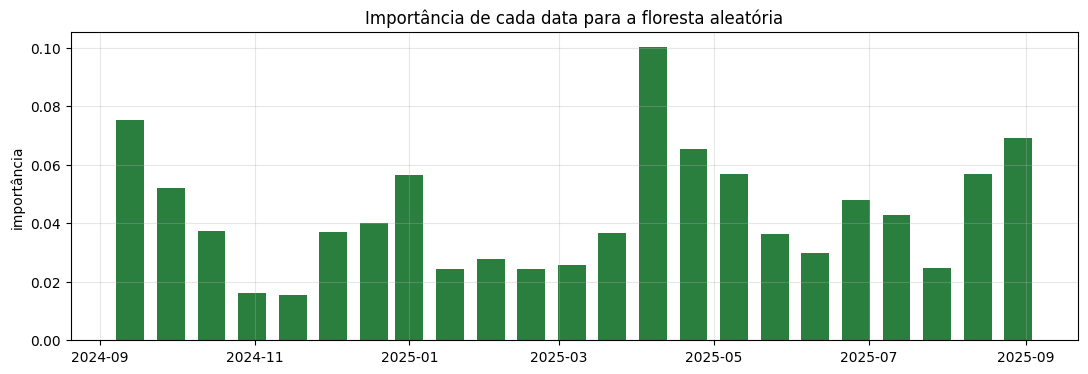

In [48]:
modelo_final = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, y)
importancia = pd.Series(modelo_final.feature_importances_, index=datas)

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(importancia.index, importancia.values, width=11, color='#2a7f3f')
ax.set_ylabel('importância')
ax.set_title('Importância de cada data para a floresta aleatória')

print('cinco datas mais importantes:')
print(importancia.sort_values(ascending=False).head(5).round(3).to_string())

A árvore rasa pergunta primeiro pelo NDVI do fim de agosto, no auge da seca, e separa
por um limiar negativo (−0.04) o que é água do que não é, só a lâmina d'água chega a
NDVI negativo ali. O segundo nó desse ramo isola uma amostra de `floresta` que também
caiu em NDVI negativo, um caso à parte que uma árvore de profundidade 3 acomoda como
folha própria.

No ramo maior, 23 de abril divide o que está vigoroso (agricultura e floresta, com a
segunda safra no campo) do que não está (pastagem e urbano). Dentro de cada lado, uma
data resolve o par: 1º de janeiro separa pastagem de urbano, o pasto verde na chuva, a
área construída não, e 13 de setembro separa agricultura de floresta, solo exposto de um
lado, dossel do outro.

As datas mais importantes para a floresta aleatória apontam na mesma direção: 07/04 e
23/04, no pico da safrinha, 09/05 na sua descida, e 13/09 e 29/08, nas duas pontas da
entressafra. São exatamente os momentos em que a lavoura está no extremo e a vegetação
perene não.

### 10.7 Onde o classificador erra

In [49]:
from sklearn.metrics import confusion_matrix

previsto = cross_val_predict(modelo_final, X, y, cv=cv)
classes = sorted(y.unique())
confusao = pd.DataFrame(confusion_matrix(y, previsto, labels=classes),
                        index=pd.Index(classes, name='real'), columns=classes)
confusao['acerto'] = (np.diag(confusao) / confusao.sum(axis=1)).round(2)
confusao

,agricultura,agua,floresta,pastagem,urbano,acerto
real,,,,,,
agricultura,53,0,0,3,2,0.91
agua,1,44,0,0,0,0.98
floresta,0,1,23,0,1,0.92
pastagem,8,0,1,30,3,0.71
urbano,2,1,0,7,38,0.79


`agua` (0.98) e `floresta` (0.92) quase não erram. A confusão se concentra em `pastagem`,
que acerta 0.71 e se troca com `agricultura` (8 amostras) e com `urbano` (3), e em
`urbano` (0.79), que perde 7 amostras para `pastagem`. São as mesmas sobreposições que os
perfis da seção 10.4 já mostravam: pasto seco fica parecido com área construída, e pasto
verde na estação chuvosa fica parecido com lavoura.

### 10.8 Classificar a área do caso

O equivalente a "classificar a imagem inteira" do roteiro, sem consulta nova, já que os pixels
da área da seção 9 já estão em memória, com as mesmas datas. A consulta de lá trouxe
`SCL`, então a mesma máscara e a mesma interpolação da seção 10.3 valem aqui.

1903 pixels classificados de 1903

agricultura    1466
floresta        276
pastagem        161


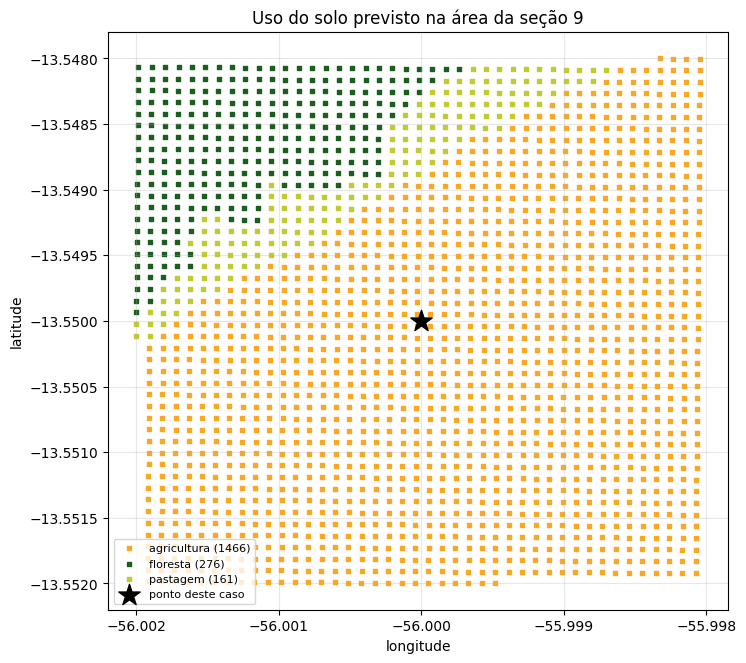

In [50]:
largo_area = area.df(format='wide')                     # NDVI e SCL, por pixel
ndvi_area = largo_area['NDVI'].where(largo_area[QUALIDADE].isin(SCL_LIMPOS))
ndvi_area = ndvi_area.interpolate(method='time', limit_direction='both')

X_area = ndvi_area.T.dropna()
X_area.columns = X.columns
classe_pixel = pd.Series(modelo_final.predict(X_area), index=X_area.index)

print(f'{len(X_area)} pixels classificados de {largo_area["NDVI"].shape[1]}\n')
print(classe_pixel.value_counts().to_string())

fig, ax = plt.subplots(figsize=(8, 7.5))
for classe, grupo in classe_pixel.groupby(classe_pixel):
    lon = [p[0] for p in grupo.index]
    lat = [p[1] for p in grupo.index]
    ax.scatter(lon, lat, s=9, marker='s', color=CORES[classe], label=f'{classe} ({len(grupo)})')
ax.scatter([LONGITUDE], [LATITUDE], marker='*', s=260, color='black', zorder=5,
           label='ponto deste caso')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title('Uso do solo previsto na área da seção 9')
ax.ticklabel_format(useOffset=False, style='plain')
ax.xaxis.set_major_locator(plt.MaxNLocator(5))
ax.legend(fontsize=8, loc='lower left')
plt.show()

floresta: NDVI médio entre 0.66 e 0.89 nas outras 22 datas
floresta: 0.81 em 02/02/2025 e 0.48 em 18/02/2025
pastagem: 0.76 em 02/02/2025 e 0.41 em 18/02/2025
datas em que a pastagem fica entre agricultura e floresta: 22 de 23


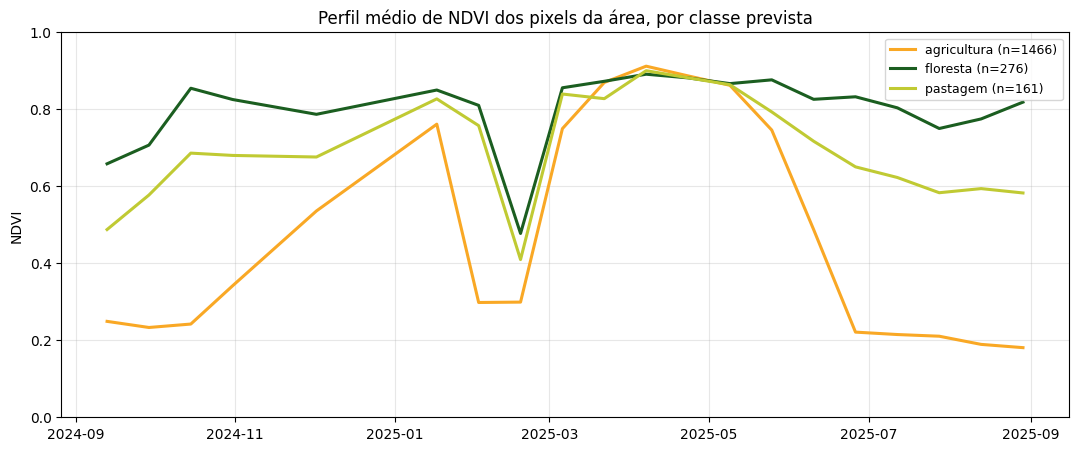

In [51]:
# Perfil medio de NDVI dos pixels da area, agrupados pela classe prevista.
fig, ax = plt.subplots(figsize=(13, 5))
for classe, grupo in X_area.groupby(classe_pixel):
    ax.plot(datas, grupo.mean(), color=CORES[classe], linewidth=2.2,
            label=f'{classe} (n={len(grupo)})')
ax.set_ylabel('NDVI'); ax.set_ylim(0, 1)
ax.set_title('Perfil médio de NDVI dos pixels da área, por classe prevista')
ax.legend(fontsize=9)

perfil = X_area.groupby(classe_pixel).mean().T          # data x classe
perfil.index = datas
sem_18_02 = perfil['floresta'].drop(pd.Timestamp('2025-02-18'))
print(f'floresta: NDVI médio entre {sem_18_02.min():.2f} e {sem_18_02.max():.2f} '
      f'nas outras {len(sem_18_02)} datas')
for classe in ('floresta', 'pastagem'):
    print(f'{classe}: {perfil.loc["2025-02-02", classe]:.2f} em 02/02/2025 e '
          f'{perfil.loc["2025-02-18", classe]:.2f} em 18/02/2025')
entre = ((perfil['pastagem'] - perfil['agricultura']) * (perfil['pastagem'] - perfil['floresta']) < 0)
print(f'datas em que a pastagem fica entre agricultura e floresta: {int(entre.sum())} de {len(perfil)}')
plt.show()

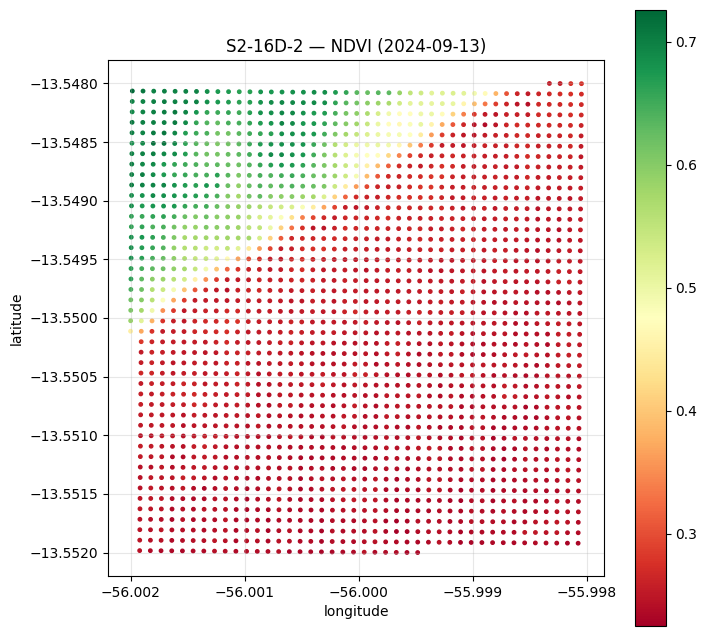

In [52]:
# A area na entressafra: solo exposto contra vegetacao.
area.plot_map('NDVI', datetime=f'{datas[0]:%Y-%m-%d}', cmap='RdYlGn', markersize=6)
plt.show()

Os dois gráficos acima sustentam o mapa de classes. Os pixels previstos como `floresta`
têm NDVI alto e estável o ano inteiro, entre 0.66 e 0.89, sem o vale da entressafra nem a
queda da colheita que a `agricultura` mostra em fevereiro, e ocupam o canto noroeste da
área. A exceção é uma queda isolada em 18/02, de 0.81 para 0.48, que atinge no mesmo dia a
`pastagem` (de 0.76 para 0.41), simultaneidade compatível com resíduo atmosférico que a
máscara não removeu, e não com fenologia. O mapa
de 13 de setembro mostra esse mesmo bloco verde enquanto o resto da área está em solo exposto: é vegetação perene, e a caixa a atravessa. A mediana
da seção 9 não revelou isso porque é robusta justamente a uma minoria de pixels
diferentes, já o classificador, pixel a pixel, revela.

Os pixels previstos como `pastagem` concentram-se na faixa entre os dois blocos, e o seu
perfil médio fica entre os outros dois em 22 das 23 datas. Provavelmente são pixels de
borda misturando lavoura e vegetação, cujo perfil intermediário cai mais perto de
pastagem do que de qualquer das duas.

## 11. Síntese

A tabela abaixo resume cada safra do período:

In [53]:
resumo = []
for ano in ANOS_AGRICOLAS:
    no_ano = ndvi[f'{ano}-09-01':f'{ano + 1}-08-31']
    safra = no_ano.dropna()
    if len(safra) < 5:
        continue
    resumo.append({
        'ano agrícola': f'{ano}/{str(ano + 1)[2:]}',
        'composições': len(no_ano),
        'observações úteis': len(safra),
        'NDVI médio': round(float(safra.mean()), 3),
        'NDVI de pico': round(float(safra.max()), 3),
        'data do pico': f'{safra.idxmax():%d/%m/%Y}',
        'NDVI mínimo': round(float(safra.min()), 3),
        'data do mínimo': f'{safra.idxmin():%d/%m/%Y}',
        'amplitude': round(float(safra.max() - safra.min()), 3),
    })

pd.DataFrame(resumo).set_index('ano agrícola')

,composições,observações úteis,NDVI médio,NDVI de pico,data do pico,NDVI mínimo,data do mínimo,amplitude
ano agrícola,,,,,,,,
2022/23,23,20,0.532,0.923,07/04/2023,0.210,14/09/2022,0.713
2023/24,23,21,0.512,0.909,19/12/2023,0.234,28/08/2024,0.675
2024/25,23,18,0.498,0.916,07/04/2025,0.171,29/08/2025,0.745


As três safras têm mínimo entre 0.17 e 0.24, todos compatíveis com solo exposto na
entressafra, e todos entre o fim de agosto e meados de setembro. Nenhuma composição do
período ficou com NDVI baixo demais para ser solo, o que também é um resultado da máscara
da seção 6: as dez composições que o `SCL` reprovou foram descartadas antes de qualquer
estatística. Essas composições foram seis de nuvem (cinco de probabilidade alta e uma de média), uma de cirrus fino
e três não classificadas, o código 7 que a seção 6 descarta por precaução. Sem ela, a série teria a composição de 01/11/2022, que o `SCL`
classifica como nuvem de probabilidade alta (seção 3), com NDVI calculado de 0.011
(seção 4).

O que separa os três anos é sobretudo em qual safra caiu o máximo — na safrinha de abril
em 2022/23 e 2024/25, na soja de dezembro em 2023/24 — e quantas composições
sobreviveram à máscara, entre 18 e 21 das 23 de cada ano.

## 12. O que este caso demonstra

| Etapa | Recurso do cliente reformulado |
| --- | --- |
| Consulta multi-banda | `coverage.ts(attributes=[...])` — uma requisição, várias bandas |
| Alinhamento por data | `ts.df(format='wide')` → `DataFrame` com `DatetimeIndex` |
| Álgebra entre bandas | operação vetorizada direta, sem casar listas na mão |
| Metadados de imagem | `apply_scale` / `mask_nodata` opcionais, com detecção de dupla escala |
| Qualidade | a banda `SCL` como filtro por composição, conferida contra `CLEAROB`/`TOTALOB` |
| Fatiamento temporal | `serie['2024-09':'2025-08']`, sintaxe nativa de `pandas` |
| Agregação | `resample('MS').mean()`, `groupby` sobre o índice |
| Do pixel para a área | `ts(geom=...)` e `summarize()`, com a estatística por data calculada no servidor |
| Dimensão espacial | `plot_map(datetime=...)` — onde está a heterogeneidade, não só quanta |
| Confronto com a imagem | o mesmo recorte lido do COG com `rasterio` e `Window`, reprojetado sobre o mapa do cliente |
| Exportação em GeoTIFF | `to_xarray(grid=True)` e `to_geotiff()` — raster multibanda, uma banda por data |
| Figuras navegáveis | `plot(interactive=True)` e `plot_map(interactive=True)` — o mesmo gráfico e o mesmo mapa em `plotly` e `folium`, com a série de cada pixel a um clique |
| Série como atributo | uma consulta por amostra traz `NDVI` e `SCL` juntos; as composições com nuvens e sombras de nuvens são mascaradas e interpoladas, e as `pandas.Series` se alinham sozinhas no `DataFrame` que vira a matriz do `scikit-learn` |

Nenhuma dessas linhas precisou converter formato, procurar posições na *timeline* ou
casar valores com datas manualmente e esse era exatamente o custo imposto pelo cliente
anterior, no qual `values()` e `timeline` eram listas paralelas independentes.